**Name:** VISHNU VARDHAN G V S <br>
**Student ID**: 202411071 <p>

**Name:** PRIYANSHIBEN KA. PATEL <br>
**Student ID**: 202411009 <p>

**Name:** VYOM NARSANA <br>
**Student ID:** 202203026 <p>
**Group:** 23 <p>
**Subject**: Exploratory Data Analysis <br>
**Subject Code**: IT462 <br>

Dataset Link: https://drive.google.com/file/d/1IXpR5lNWL9c7G59-c_ZzYJD3DcTNHz2t/view?usp=drive_link

<h2> Importing libraries </h2>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import missingno as msno

In [2]:
!apt-get install git-lfs
!git clone https://github.com/Priyanshi89/EDA-Project.git

# data = pd.read_csv("https://raw.githubusercontent.com/Priyanshi89/EDA-Project/main/Allegheny-County-Cumulative_Crash-Data.csv")


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
git-lfs is already the newest version (3.0.2-1ubuntu0.3).
0 upgraded, 0 newly installed, 0 to remove and 49 not upgraded.
Cloning into 'EDA-Project'...
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 6 (delta 0), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (6/6), done.


In [3]:
%cd EDA-Project
!git lfs pull
data = pd.read_csv("Allegheny-County-Cumulative_Crash-Data.csv")
data.head()


/content/EDA-Project


<ipython-input-3-851b36428605>:3: DtypeWarning: Columns (20,21,74,78,79,80,81,82,83,84,85,184,190) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("Allegheny-County-Cumulative_Crash-Data.csv")


,_id,CRASH_CRN,DISTRICT,CRASH_COUNTY,MUNICIPALITY,POLICE_AGCY,CRASH_YEAR,CRASH_MONTH,DAY_OF_WEEK,TIME_OF_DAY,...,LANE_COUNT,RDWY_ORIENT,ROAD_OWNER,ROUTE,SPEED_LIMIT,SEGMENT,OFFSET,STREET_NAME,TOT_INJ_COUNT,SCHOOL_BUS_UNIT
0,1,2004000001,11,2,2454,02454,2004,1,5,257.0,...,2.0,E,2.0,2032,35.0,10.0,1000.0,LEWIS RUN RD,NaN,NaN
1,2,2004000010,11,2,2440,02440,2004,1,5,1027.0,...,2.0,W,3.0,NaN,35.0,NaN,NaN,COAL VALLEY RD,NaN,NaN
2,3,2004000016,11,2,2203,02203,2004,1,5,1839.0,...,2.0,W,2.0,3082,35.0,NaN,NaN,CLINTON FRANKFORT RD,NaN,NaN
3,4,2004000022,11,2,2404,02404,2004,1,6,914.0,...,2.0,N,4.0,NaN,25.0,NaN,NaN,NORTH BALPH AV,NaN,NaN
4,5,2004000030,11,2,2419,02419,2004,1,5,2230.0,...,2.0,S,4.0,NaN,20.0,NaN,NaN,THORNBERRY DR,NaN,NaN


<h2> Reading Data </h2>

<h2> Data Reading and Preprocessing </h2>

In [4]:
data.describe()

,_id,CRASH_CRN,DISTRICT,CRASH_COUNTY,MUNICIPALITY,CRASH_YEAR,CRASH_MONTH,DAY_OF_WEEK,TIME_OF_DAY,HOUR_OF_DAY,...,RDWY_SEQ_NUM,ADJ_RDWY_SEQ,ACCESS_CTRL,ROADWAY_COUNTY,LANE_COUNT,ROAD_OWNER,SPEED_LIMIT,SEGMENT,OFFSET,TOT_INJ_COUNT
count,238582.000000,2.385820e+05,238582.0,238582.0,238582.000000,238582.000000,238582.000000,238582.000000,238431.000000,238431.000000,...,232424.000000,213628.000000,121302.000000,232425.000000,232401.000000,232424.000000,225602.000000,138584.000000,148060.000000,80754.000000
mean,119291.500000,2.013508e+09,11.0,2.0,2288.426147,2013.378109,6.581507,4.143502,1445.531265,14.159681,...,3.169974,3.280399,2.277127,2.022837,3.512218,2.852911,34.440940,221.613419,1001.996008,0.532197
std,68872.835299,5.642491e+06,0.0,0.0,120.440481,5.705368,3.561530,1.968479,1241.318352,12.336404,...,0.522517,0.577820,1.031367,1.178770,11.244462,1.169457,11.401586,241.600522,990.631832,0.810571
min,1.000000,2.004000e+09,11.0,2.0,2101.000000,2004.000000,1.000000,1.000000,0.000000,0.000000,...,3.000000,3.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,59646.250000,2.008138e+09,11.0,2.0,2207.000000,2008.000000,3.000000,2.000000,851.000000,8.000000,...,3.000000,3.000000,1.000000,2.000000,2.000000,2.000000,25.000000,30.000000,0.000000,0.000000
50%,119291.500000,2.013130e+09,11.0,2.0,2301.000000,2013.000000,7.000000,4.000000,1422.000000,14.000000,...,3.000000,3.000000,3.000000,2.000000,2.000000,2.000000,35.000000,113.000000,762.000000,0.000000
75%,178936.750000,2.018099e+09,11.0,2.0,2407.000000,2018.000000,10.000000,6.000000,1759.000000,17.000000,...,3.000000,3.000000,3.000000,2.000000,2.000000,4.000000,40.000000,340.000000,1684.000000,1.000000
max,238582.000000,2.024024e+09,11.0,2.0,2491.000000,2023.000000,12.000000,7.000000,9999.000000,99.000000,...,11.000000,10.000000,3.000000,66.000000,99.000000,9.000000,75.000000,8046.000000,6926.000000,30.000000


In [5]:
data.columns

Index(['_id', 'CRASH_CRN', 'DISTRICT', 'CRASH_COUNTY', 'MUNICIPALITY',
       'POLICE_AGCY', 'CRASH_YEAR', 'CRASH_MONTH', 'DAY_OF_WEEK',
       'TIME_OF_DAY',
       ...
       'LANE_COUNT', 'RDWY_ORIENT', 'ROAD_OWNER', 'ROUTE', 'SPEED_LIMIT',
       'SEGMENT', 'OFFSET', 'STREET_NAME', 'TOT_INJ_COUNT', 'SCHOOL_BUS_UNIT'],
      dtype='object', length=191)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238582 entries, 0 to 238581
Columns: 191 entries, _id to SCHOOL_BUS_UNIT
dtypes: float64(115), int64(56), object(20)
memory usage: 347.7+ MB


In [7]:
data.select_dtypes(include=['object']).columns

Index(['POLICE_AGCY', 'SCH_BUS_IND', 'SCH_ZONE_IND', 'LATITUDE', 'LONGITUDE',
       'NTFY_HIWY_MAINT', 'TFC_DETOUR_IND', 'WORK_ZONE_IND', 'WORKERS_PRES',
       'WZ_CLOSE_DETOUR', 'WZ_FLAGGER', 'WZ_LAW_OFFCR_IND', 'WZ_LN_CLOSURE',
       'WZ_MOVING', 'WZ_OTHER', 'WZ_SHLDER_MDN', 'RDWY_ORIENT', 'ROUTE',
       'STREET_NAME', 'SCHOOL_BUS_UNIT'],
      dtype='object')

In [8]:
data.select_dtypes(include=['number']).columns.unique()

Index(['_id', 'CRASH_CRN', 'DISTRICT', 'CRASH_COUNTY', 'MUNICIPALITY',
       'CRASH_YEAR', 'CRASH_MONTH', 'DAY_OF_WEEK', 'TIME_OF_DAY',
       'HOUR_OF_DAY',
       ...
       'RDWY_SEQ_NUM', 'ADJ_RDWY_SEQ', 'ACCESS_CTRL', 'ROADWAY_COUNTY',
       'LANE_COUNT', 'ROAD_OWNER', 'SPEED_LIMIT', 'SEGMENT', 'OFFSET',
       'TOT_INJ_COUNT'],
      dtype='object', length=171)

In [9]:
print(data.isnull().sum())

_id                     0
CRASH_CRN               0
DISTRICT                0
CRASH_COUNTY            0
MUNICIPALITY            0
                    ...  
SEGMENT             99998
OFFSET              90522
STREET_NAME         12313
TOT_INJ_COUNT      157828
SCHOOL_BUS_UNIT    213628
Length: 191, dtype: int64


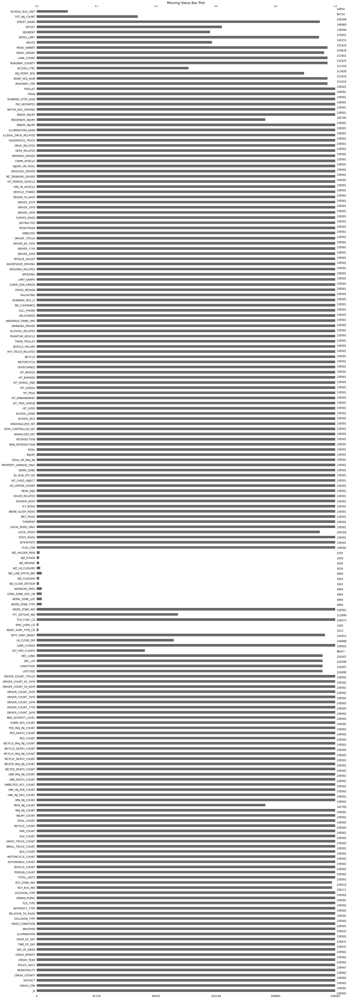

In [ ]:
plt.figure(figsize=(15, 7))
msno.bar(data, fontsize=12)
plt.title("Missing Value Bar Plot", fontsize=16)
plt.show()

<Figure size 1500x700 with 0 Axes>

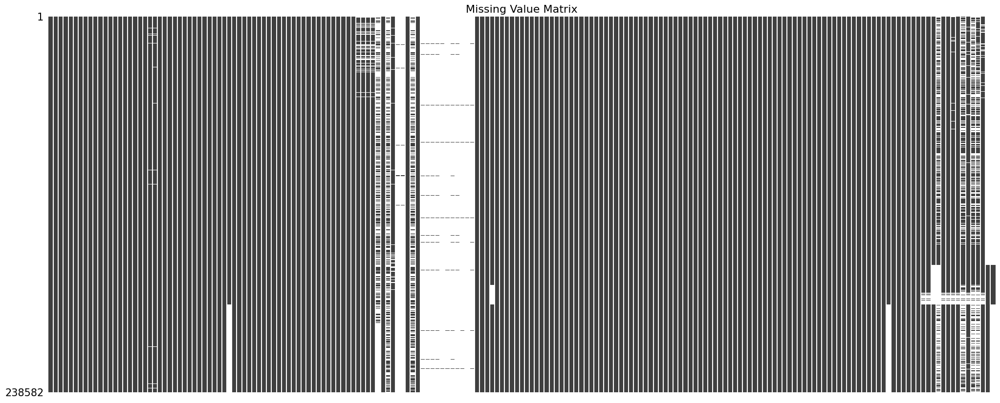

In [ ]:
plt.figure(figsize=(15, 7))
msno.matrix(data, fontsize=12, sparkline=False)
plt.title("Missing Value Matrix", fontsize=16)
plt.show()

<Figure size 1500x700 with 0 Axes>

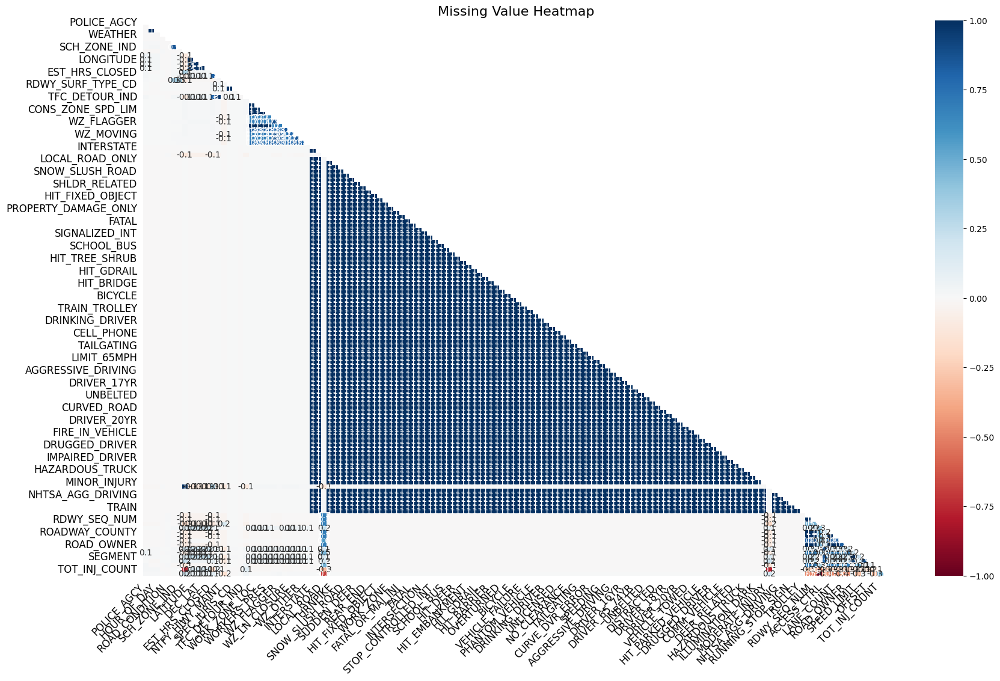

In [ ]:
plt.figure(figsize=(15, 7))
msno.heatmap(data, fontsize=12)
plt.title("Missing Value Heatmap", fontsize=16)
plt.show()

<Figure size 1500x700 with 0 Axes>

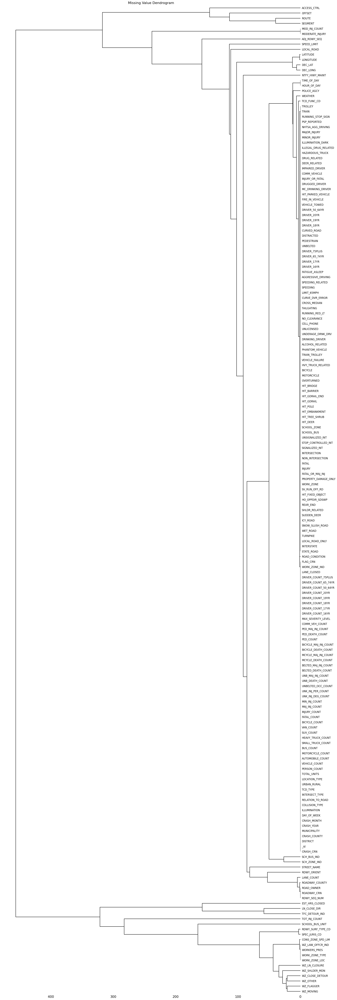

In [ ]:
plt.figure(figsize=(15, 7))
msno.dendrogram(data, fontsize=12)
plt.title("Missing Value Dendrogram", fontsize=16)
plt.show()

In [10]:
print("\nPercentage of missing values per column:")
print((data.isnull().mean() * 100).round(2))


Percentage of missing values per column:
_id                 0.00
CRASH_CRN           0.00
DISTRICT            0.00
CRASH_COUNTY        0.00
MUNICIPALITY        0.00
                   ...  
SEGMENT            41.91
OFFSET             37.94
STREET_NAME         5.16
TOT_INJ_COUNT      66.15
SCHOOL_BUS_UNIT    89.54
Length: 191, dtype: float64


In [11]:
data.duplicated().sum()

0

**There are NO DUPLICATES present in the dataset**

<Axes: >

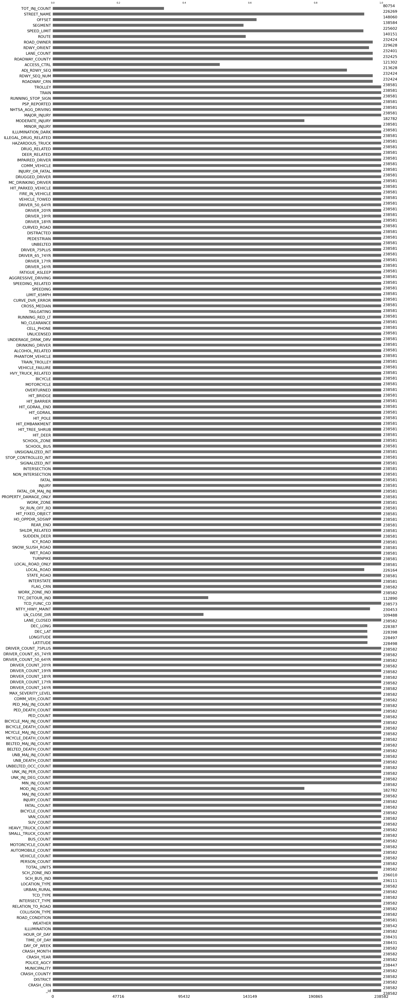

In [12]:
# Drop specific columns
dataset = data.drop(columns=['RDWY_SURF_TYPE_CD', 'SPEC_JURIS_CD', 'WZ_SHLDER_MDN', 'WZ_OTHER', 'WZ_MOVING', 'WZ_LN_CLOSURE',
                             'WZ_LAW_OFFCR_IND', 'WZ_FLAGGER', 'WZ_CLOSE_DETOUR', 'WORKERS_PRES', 'CONS_ZONE_SPD_LIM', 'WORK_ZONE_LOC',
                             'WORK_ZONE_TYPE', 'SCHOOL_BUS_UNIT', 'EST_HRS_CLOSED'])

# Identify columns with at least one non-null value
not_null_columns = dataset.columns[dataset.notnull().sum() > 0]

# Select only those columns
sorted_dataset = dataset[not_null_columns]

# Visualize missing data
import missingno as msno
msno.bar(sorted_dataset)


In [13]:



table = pd.DataFrame({
    "Column Name": sorted_dataset.columns,
    "Unique Values": [sorted_dataset[col].nunique() for col in sorted_dataset.columns],
    "Data Type": [sorted_dataset[col].dtype for col in sorted_dataset.columns]
})

In [14]:
table

,Column Name,Unique Values,Data Type
0,_id,238582,int64
1,CRASH_CRN,238582,int64
2,DISTRICT,1,int64
3,CRASH_COUNTY,1,int64
4,MUNICIPALITY,130,int64
...,...,...,...
171,SPEED_LIMIT,15,float64
172,SEGMENT,400,float64
173,OFFSET,4184,float64
174,STREET_NAME,13217,object


In [15]:
table_details = pd.DataFrame({
    "Column Name": sorted_dataset.columns,
    "Unique Values": [sorted_dataset[col].unique() for col in sorted_dataset.columns],
    "Data Type": [sorted_dataset[col].dtype for col in sorted_dataset.columns]
})

In [16]:
table_details

,Column Name,Unique Values,Data Type
0,_id,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",int64
1,CRASH_CRN,"[2004000001, 2004000010, 2004000016, 200400002...",int64
2,DISTRICT,[11],int64
3,CRASH_COUNTY,[2],int64
4,MUNICIPALITY,"[2454, 2440, 2203, 2404, 2419, 2111, 2435, 243...",int64
...,...,...,...
171,SPEED_LIMIT,"[35.0, 25.0, 20.0, 30.0, 40.0, 45.0, 55.0, nan...",float64
172,SEGMENT,"[10.0, nan, 120.0, 70.0, 54.0, 280.0, 80.0, 25...",float64
173,OFFSET,"[1000.0, nan, 1200.0, 2123.0, 0.0, 3012.0, 192...",float64
174,STREET_NAME,"[LEWIS RUN RD, COAL VALLEY RD, CLINTON FRANKFO...",object


<h2> Filling Missing values using bfill and ffill </h2>

<ipython-input-17-a88c29d37df4>:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  sorted_dataset.fillna(method='bfill',inplace=True)
<ipython-input-17-a88c29d37df4>:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  sorted_dataset.fillna(method='ffill',inplace=True)


<Axes: >

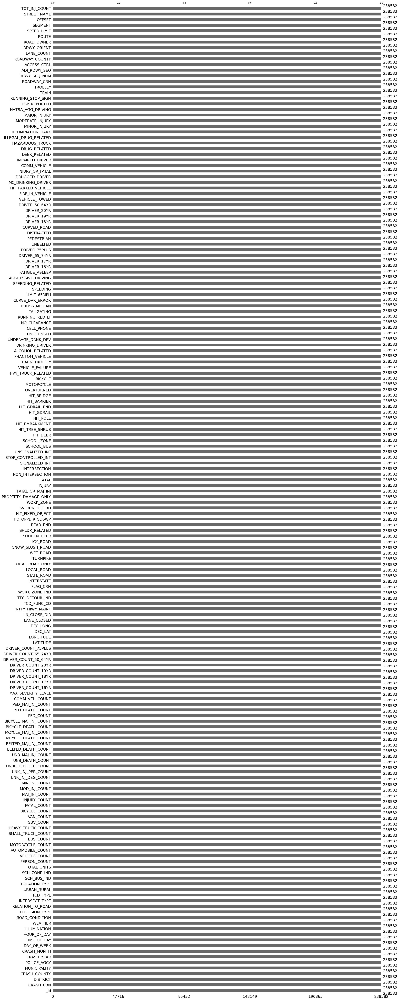

In [17]:
sorted_dataset.fillna(method='bfill',inplace=True)
sorted_dataset.fillna(method='ffill',inplace=True)
msno.bar(sorted_dataset)

In [18]:
sorted_dataset.isnull().sum().sum()

0

**There are NO MISSING VALUES present in the dataset**

<h2> Separate Out categorical and Numarical columns </h2>

In [19]:
cat_columns = list(sorted_dataset.select_dtypes(include=['object']).columns)
num_columns = list(sorted_dataset.select_dtypes(include=['number']).columns)
print(cat_columns)
print(num_columns)


['POLICE_AGCY', 'SCH_BUS_IND', 'SCH_ZONE_IND', 'LATITUDE', 'LONGITUDE', 'NTFY_HIWY_MAINT', 'TFC_DETOUR_IND', 'WORK_ZONE_IND', 'RDWY_ORIENT', 'ROUTE', 'STREET_NAME']
['_id', 'CRASH_CRN', 'DISTRICT', 'CRASH_COUNTY', 'MUNICIPALITY', 'CRASH_YEAR', 'CRASH_MONTH', 'DAY_OF_WEEK', 'TIME_OF_DAY', 'HOUR_OF_DAY', 'ILLUMINATION', 'WEATHER', 'ROAD_CONDITION', 'COLLISION_TYPE', 'RELATION_TO_ROAD', 'INTERSECT_TYPE', 'TCD_TYPE', 'URBAN_RURAL', 'LOCATION_TYPE', 'TOTAL_UNITS', 'PERSON_COUNT', 'VEHICLE_COUNT', 'AUTOMOBILE_COUNT', 'MOTORCYCLE_COUNT', 'BUS_COUNT', 'SMALL_TRUCK_COUNT', 'HEAVY_TRUCK_COUNT', 'SUV_COUNT', 'VAN_COUNT', 'BICYCLE_COUNT', 'FATAL_COUNT', 'INJURY_COUNT', 'MAJ_INJ_COUNT', 'MOD_INJ_COUNT', 'MIN_INJ_COUNT', 'UNK_INJ_DEG_COUNT', 'UNK_INJ_PER_COUNT', 'UNBELTED_OCC_COUNT', 'UNB_DEATH_COUNT', 'UNB_MAJ_INJ_COUNT', 'BELTED_DEATH_COUNT', 'BELTED_MAJ_INJ_COUNT', 'MCYCLE_DEATH_COUNT', 'MCYCLE_MAJ_INJ_COUNT', 'BICYCLE_DEATH_COUNT', 'BICYCLE_MAJ_INJ_COUNT', 'PED_COUNT', 'PED_DEATH_COUNT', 'PED_MA

In [20]:
unique_count = len(sorted_dataset["SPEED_LIMIT"].unique())
print(unique_count)


15


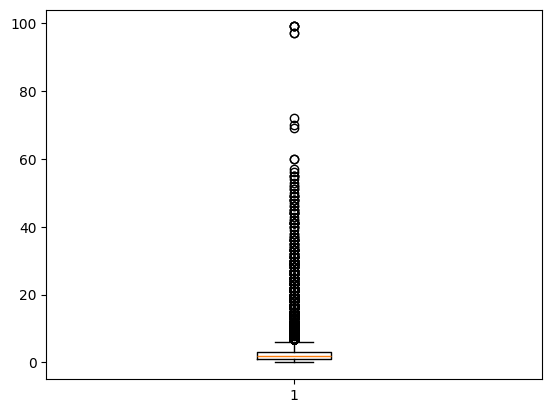

In [21]:
plt.boxplot(sorted_dataset["PERSON_COUNT"])
plt.show()

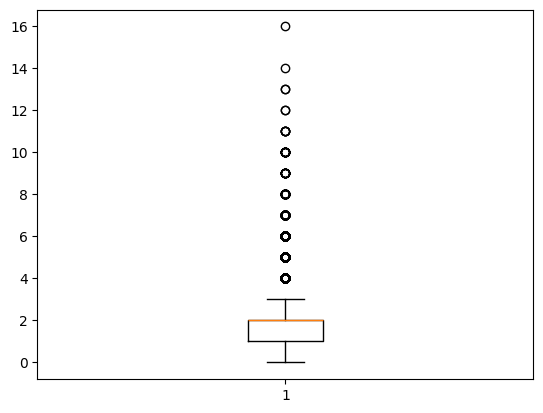

In [ ]:
plt.boxplot(sorted_dataset["VEHICLE_COUNT"])
plt.show()

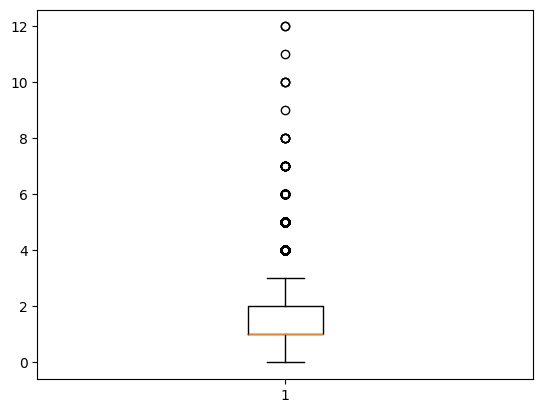

In [ ]:
plt.boxplot(sorted_dataset["AUTOMOBILE_COUNT"])
plt.show()

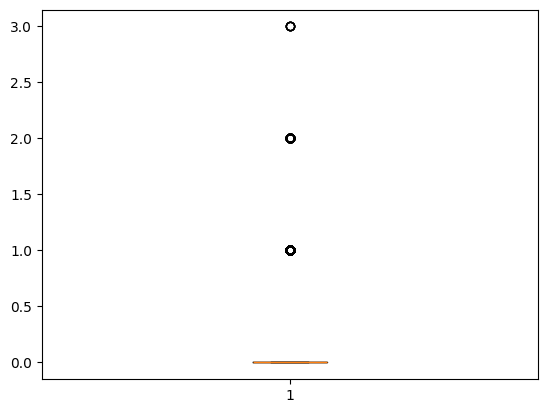

In [ ]:
plt.boxplot(sorted_dataset["MOTORCYCLE_COUNT"])
plt.show()

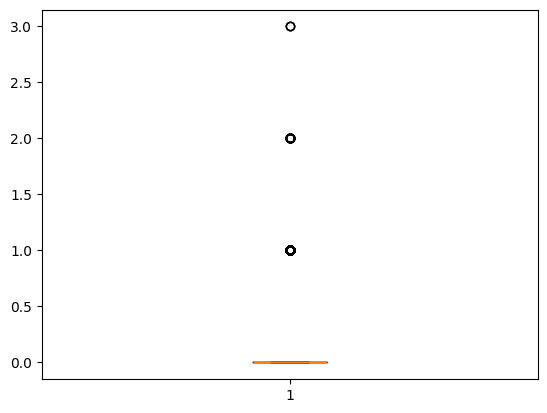

In [ ]:
plt.boxplot(sorted_dataset["BUS_COUNT"])
plt.show()

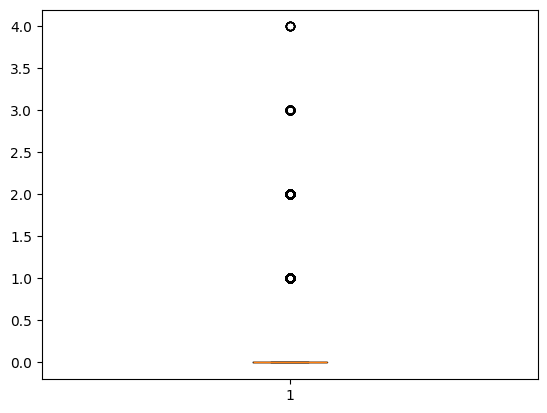

In [ ]:
plt.boxplot(sorted_dataset["SMALL_TRUCK_COUNT"])
plt.show()

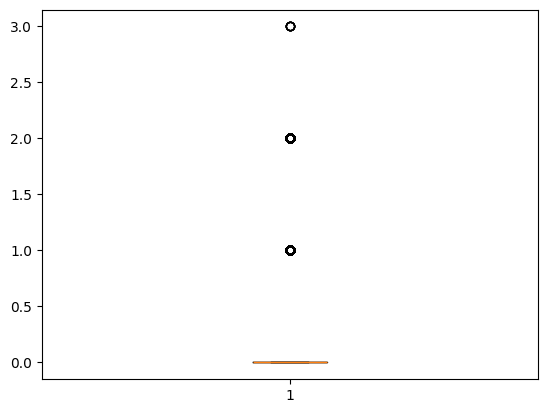

In [ ]:
plt.boxplot(sorted_dataset["HEAVY_TRUCK_COUNT"])
plt.show()

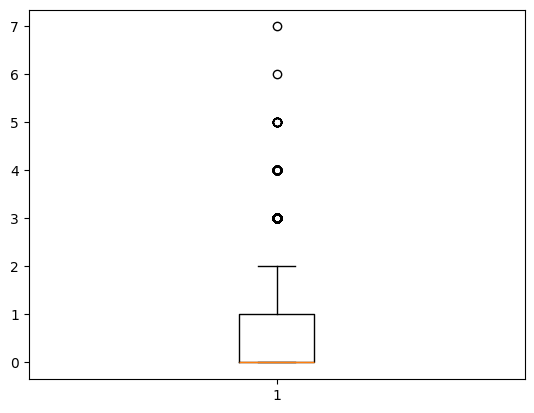

In [ ]:
plt.boxplot(sorted_dataset["SUV_COUNT"])
plt.show()

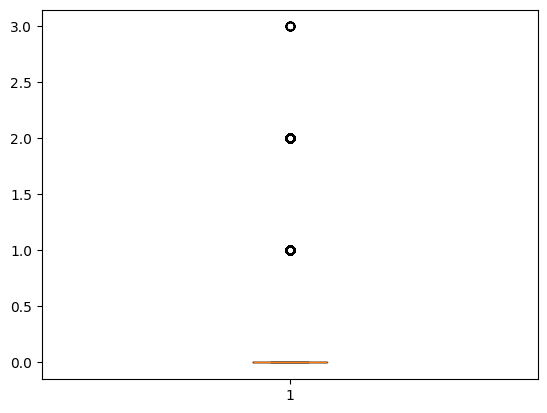

In [ ]:
plt.boxplot(sorted_dataset["VAN_COUNT"])
plt.show()

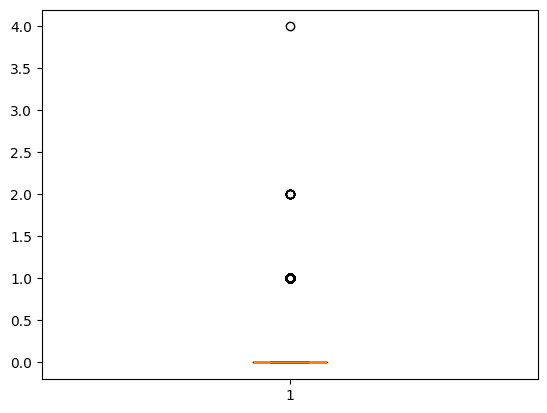

In [ ]:
plt.boxplot(sorted_dataset["BICYCLE_COUNT"])
plt.show()

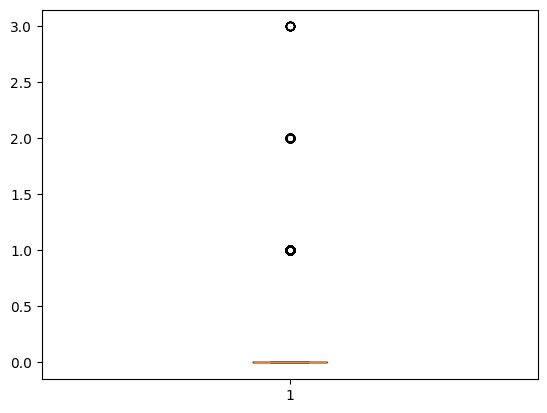

In [ ]:
plt.boxplot(sorted_dataset["FATAL_COUNT"])
plt.show()

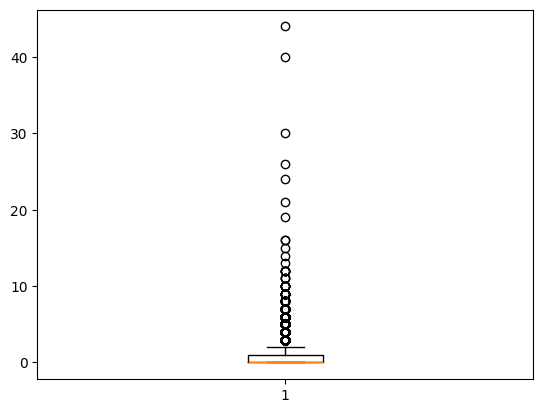

In [ ]:
plt.boxplot(sorted_dataset["INJURY_COUNT"])
plt.show()

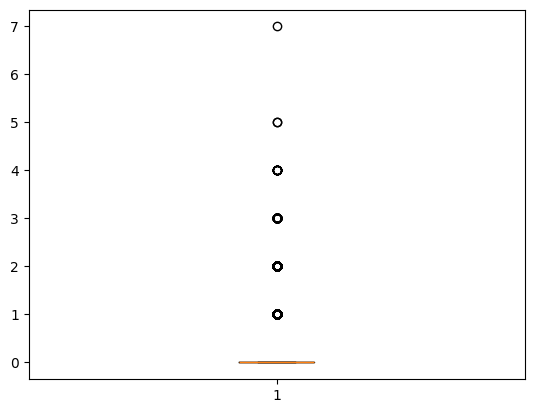

In [ ]:
plt.boxplot(sorted_dataset["MAJ_INJ_COUNT"])
plt.show()

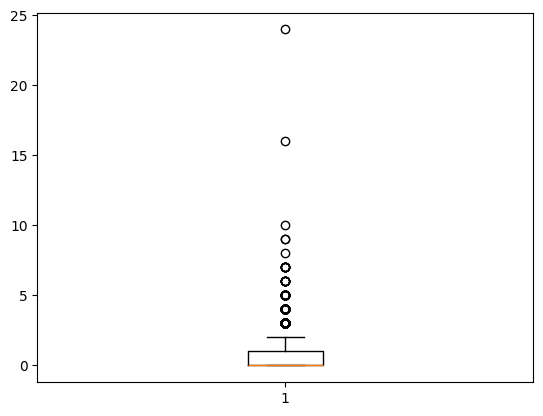

In [ ]:
plt.boxplot(sorted_dataset["MOD_INJ_COUNT"])
plt.show()

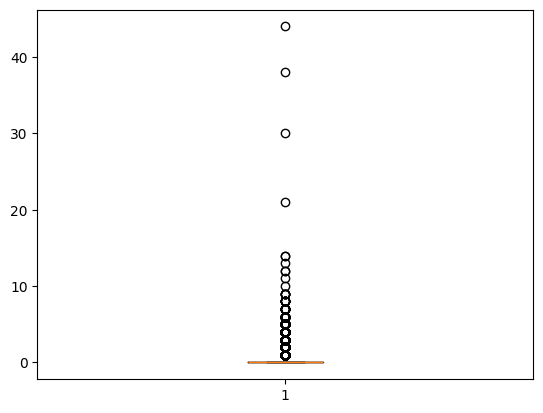

In [ ]:
plt.boxplot(sorted_dataset["MIN_INJ_COUNT"])
plt.show()

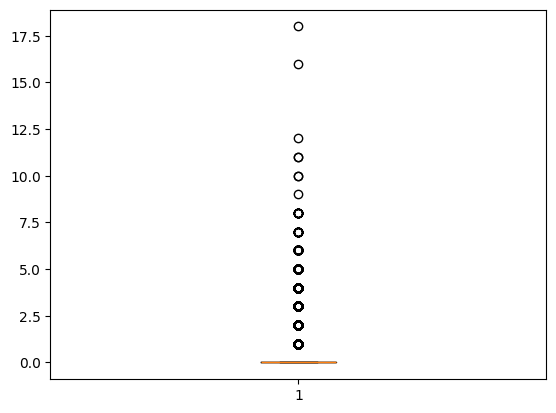

In [ ]:
plt.boxplot(sorted_dataset["UNK_INJ_DEG_COUNT"])
plt.show()

In [22]:
df = sorted_dataset.copy()

In [23]:
df

,_id,CRASH_CRN,DISTRICT,CRASH_COUNTY,MUNICIPALITY,POLICE_AGCY,CRASH_YEAR,CRASH_MONTH,DAY_OF_WEEK,TIME_OF_DAY,...,ROADWAY_COUNTY,LANE_COUNT,RDWY_ORIENT,ROAD_OWNER,ROUTE,SPEED_LIMIT,SEGMENT,OFFSET,STREET_NAME,TOT_INJ_COUNT
0,1,2004000001,11,2,2454,02454,2004,1,5,257.0,...,2.0,2.0,E,2.0,2032,35.0,10.0,1000.0,LEWIS RUN RD,0.0
1,2,2004000010,11,2,2440,02440,2004,1,5,1027.0,...,2.0,2.0,W,3.0,3082,35.0,120.0,1200.0,COAL VALLEY RD,0.0
2,3,2004000016,11,2,2203,02203,2004,1,5,1839.0,...,2.0,2.0,W,2.0,3082,35.0,120.0,1200.0,CLINTON FRANKFORT RD,0.0
3,4,2004000022,11,2,2404,02404,2004,1,6,914.0,...,2.0,2.0,N,4.0,0051,25.0,120.0,1200.0,NORTH BALPH AV,0.0
4,5,2004000030,11,2,2419,02419,2004,1,5,2230.0,...,2.0,2.0,S,4.0,0051,20.0,120.0,1200.0,THORNBERRY DR,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238577,238578,2024023005,11,2,2435,68B03,2023,11,7,1734.0,...,2.0,2.0,W,1.0,0376,55.0,665.0,997.0,PENN LINCOLN PY,1.0
238578,238579,2024023006,11,2,2116,68B03,2023,12,7,2207.0,...,2.0,3.0,N,1.0,0279,55.0,52.0,322.0,NORTH HILLS EX,0.0
238579,238580,2024023648,11,2,2213,02213,2023,12,2,620.0,...,2.0,2.0,W,4.0,0279,25.0,52.0,322.0,PATTON DR,0.0
238580,238581,2024023829,11,2,2215,02215,2023,5,3,1646.0,...,2.0,4.0,S,4.0,0279,35.0,52.0,322.0,MOUNT NEBO RD,0.0


# Data Vizualization

## Distribution of Crash Severity

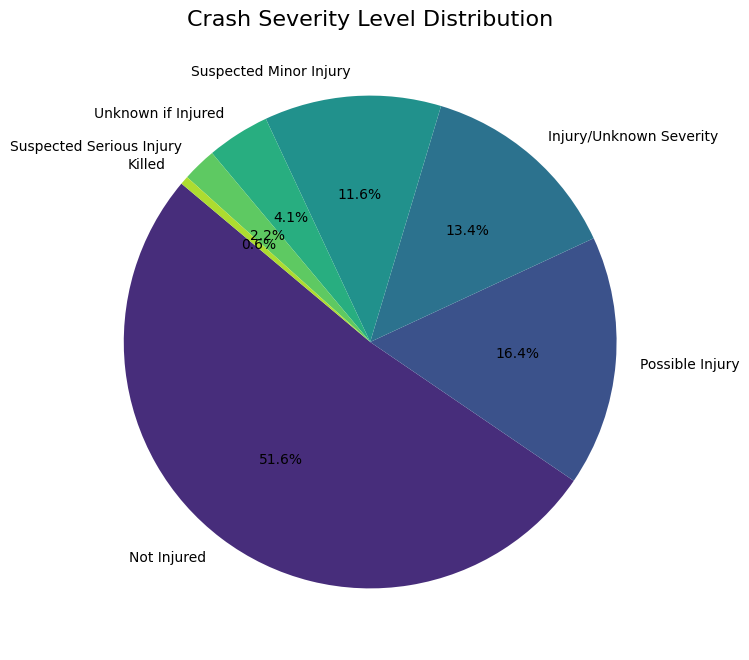

In [ ]:
severity_dict = {
    0: 'Not Injured',
    1: 'Killed',
    2: 'Suspected Serious Injury',
    3: 'Suspected Minor Injury',
    4: 'Possible Injury',
    8: 'Injury/Unknown Severity',
    9: 'Unknown if Injured'
}

# Calculate the severity level counts
severity_counts = df['MAX_SEVERITY_LEVEL'].value_counts()

# Create a list of labels for the pie chart, based on severity_dict
labels = [severity_dict.get(level, f'Unknown ({level})') for level in severity_counts.index]

# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(severity_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis', len(severity_counts)))
plt.title('Crash Severity Level Distribution', fontsize=16)

# Display the pie chart
plt.show()

## Yearly, Monthly , Weekly and Daily distributions

<ipython-input-44-7582b1c0deb9>:31: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_temp[col].dropna(), ax=ax, shade=True, color='skyblue', edgecolor='black')


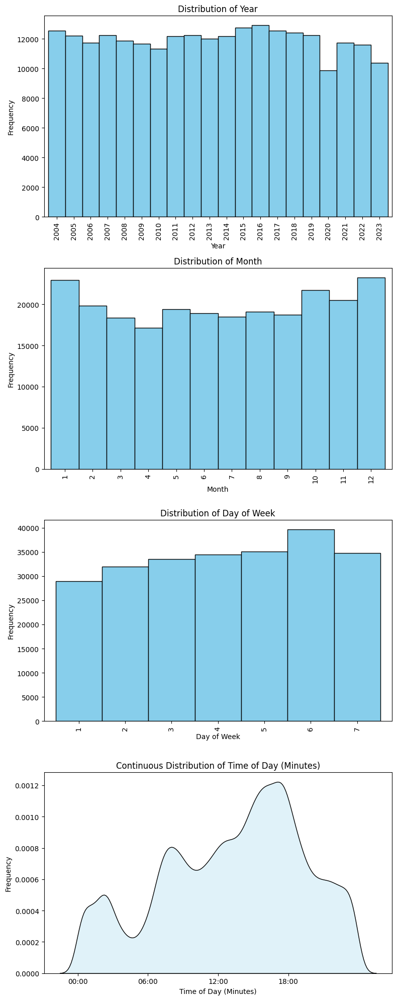

In [ ]:
# Transformations
df_temp = df.copy()

# Convert TIME_OF_DAY to minutes, replacing 9999 with NaN
df_temp['TIME_OF_DAY_MINUTES'] = df_temp['TIME_OF_DAY'].apply(lambda x: (x // 100) * 60 + (x % 100) if x != 9999 else None)

# Function to convert minutes into HH:MM format
def minutes_to_time(minutes):
    if pd.isna(minutes):
        return None
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02}:{mins:02}"

# Convert the minutes into HH:MM format for x-axis labels
df_temp['TIME_OF_DAY_FORMATTED'] = df_temp['TIME_OF_DAY_MINUTES'].apply(minutes_to_time)

# Plotting the distributions
quantities_to_plot = [
    ('CRASH_YEAR', 'Year'),
    ('CRASH_MONTH', 'Month'),
    ('DAY_OF_WEEK', 'Day of Week'),
    ('TIME_OF_DAY_MINUTES', 'Time of Day (Minutes)'),
]

fig, axes = plt.subplots(len(quantities_to_plot), 1, figsize=(8, 20), tight_layout=True)

for ax, (col, label) in zip(axes, quantities_to_plot):
    if label == 'Time of Day (Minutes)':
        # Continuous plot for Time of Day with formatted x-axis
        sns.kdeplot(df_temp[col].dropna(), ax=ax, shade=True, color='skyblue', edgecolor='black')
        ax.set_title(f"Continuous Distribution of {label}")

        # Set the x-axis ticks to only show 00:00, 06:00, 12:00, 18:00
        ax.set_xticks([i * 60 for i in range(0, 24, 6)])  # Every 6 hours: 0, 6, 12, 18
        ax.set_xticklabels([minutes_to_time(i * 60) for i in range(0, 24, 6)])

    else:
        # Bar plot for discrete data, with bars touching each other
        df_temp[col].dropna().value_counts().sort_index().plot(kind='bar', ax=ax, color='skyblue', edgecolor='black', width=1)
        ax.set_title(f"Distribution of {label}")

    ax.set_xlabel(label)
    ax.set_ylabel("Density" if label == 'TIME_OF_DAY_MINUTES' else "Frequency")

plt.show()

## Illumination, Weather and Road Condition Distribution

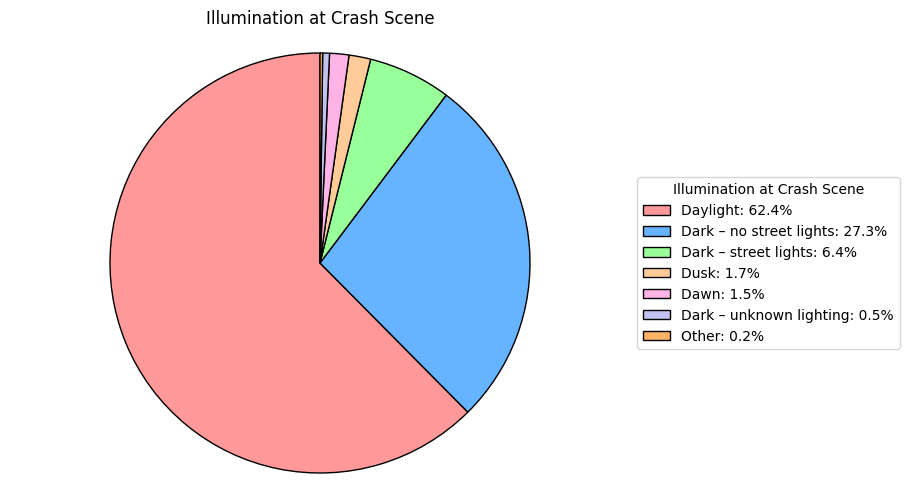

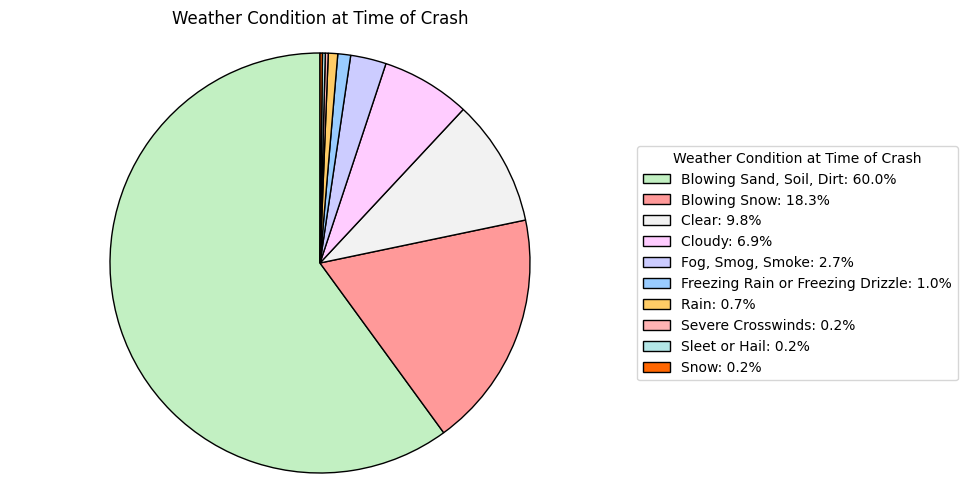

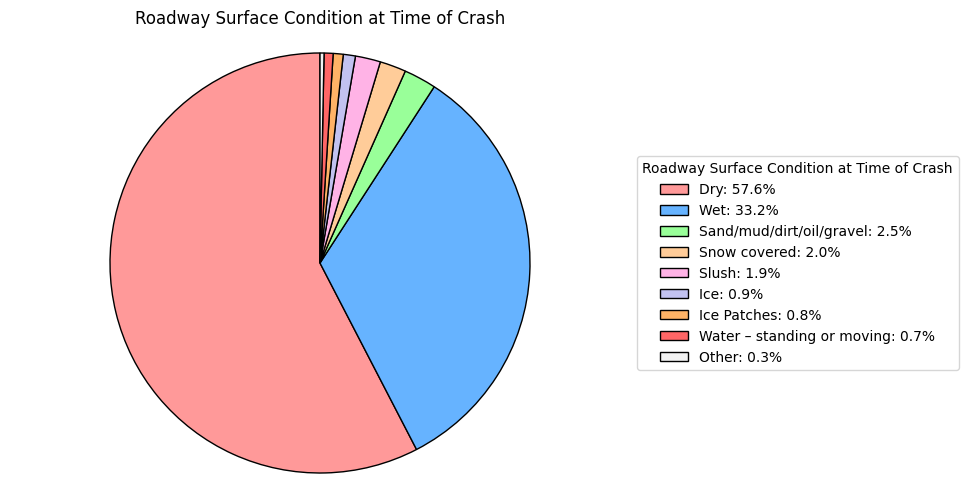

In [ ]:
# Define the valid values for each column
valid_illumination = [1, 2, 3, 4, 5, 6, 8]
valid_weather = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
valid_road_condition = [0, 1, 2, 3, 4, 5, 6, 7, 8]

# Labels for each column (updated for numerical data)
illumination_labels = ['Daylight', 'Dark – no street lights', 'Dark – street lights', 'Dusk', 'Dawn',
                        'Dark – unknown lighting', 'Other']
weather_labels = ['Blowing Sand, Soil, Dirt', 'Blowing Snow', 'Clear', 'Cloudy', 'Fog, Smog, Smoke',
                  'Freezing Rain or Freezing Drizzle', 'Rain', 'Severe Crosswinds', 'Sleet or Hail', 'Snow']
road_condition_labels = ['Dry', 'Wet', 'Sand/mud/dirt/oil/gravel', 'Snow covered', 'Slush', 'Ice',
                         'Ice Patches', 'Water – standing or moving', 'Other']

# Function to plot pie chart
def plot_pie(column, title, labels, valid_values, colors=None):
    plt.figure(figsize=(8, 6))

    # Filter the data to keep only valid values
    filtered_data = df[df[column].isin(valid_values)]

    # Count the occurrences of each valid value
    value_counts = filtered_data[column].value_counts()

    # Adjust the number of labels to match the unique values
    unique_values = value_counts.index

    # Dynamically adjust the labels to match the unique values present
    adjusted_labels = [labels[i] for i in range(len(labels)) if valid_values[i] in unique_values]

    # Plot pie chart without autopct
    wedges, texts = plt.pie(
        value_counts,
        labels=None,  # No labels on the pie chart itself
        startangle=90,
        colors=colors,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1},
        pctdistance=0.85
    )

    # Adjust label text settings
    for text in texts:
        text.set(fontsize=10)

    # Title and legend
    plt.title(title)
    plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle

    # Prepare the legend with percentages and labels
    legend_labels = [f'{label}: {percent:.1f}%' for label, percent in zip(adjusted_labels, value_counts / value_counts.sum() * 100)]

    # Adding legend with percentages
    plt.legend(wedges, legend_labels, title=title, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

# Plotting pie charts for ILLUMINATION, WEATHER, and ROAD_CONDITION
plot_pie("ILLUMINATION", "Illumination at Crash Scene", illumination_labels, valid_illumination, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366'])
plot_pie("WEATHER", "Weather Condition at Time of Crash", weather_labels, valid_weather, colors=['#c2f0c2','#ff9999','#f2f2f2','#ffccff','#ccccff','#99ccff','#ffcc66','#ffb3b3','#b3e6e6','#ff6600','#d9d9d9','#f2f2f2'])
plot_pie("ROAD_CONDITION", "Roadway Surface Condition at Time of Crash", road_condition_labels, valid_road_condition, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666','#f2f2f2'])

## COLLISION_TYPE, RELATION_TO_ROAD, INTERSECT_TYPE, and TCD_TYPE Distributions

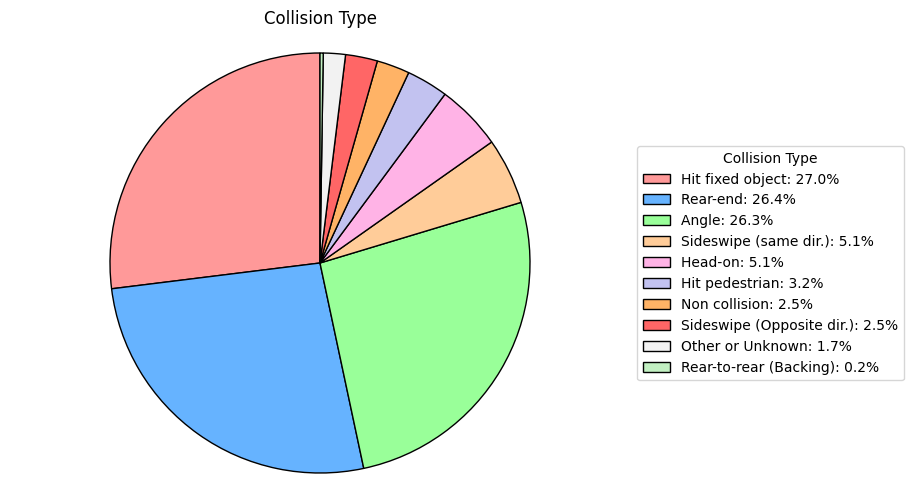

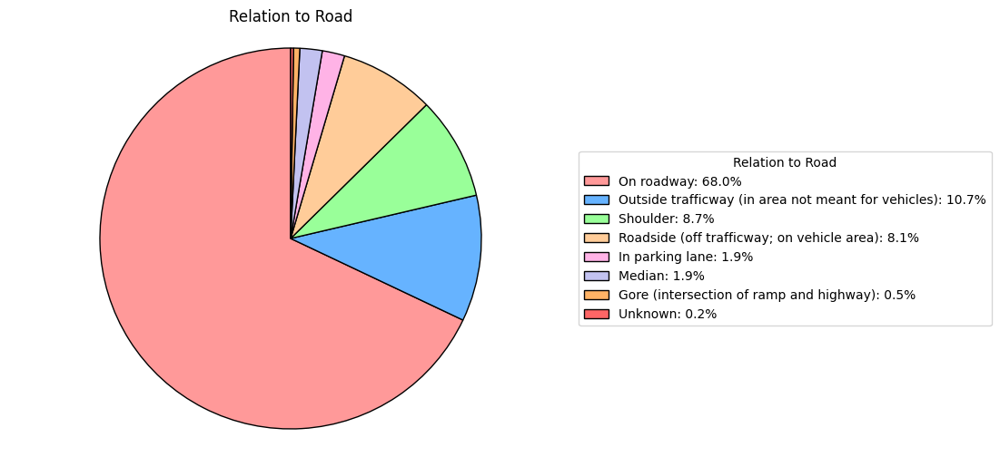

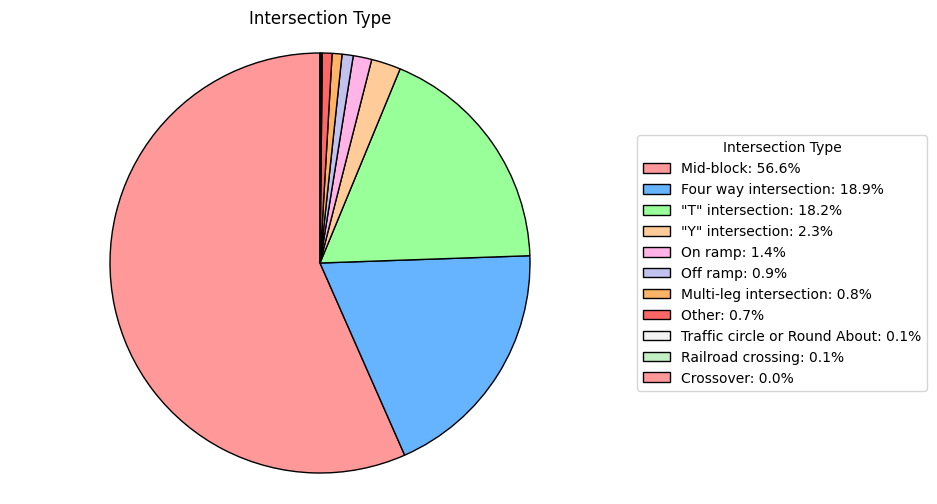

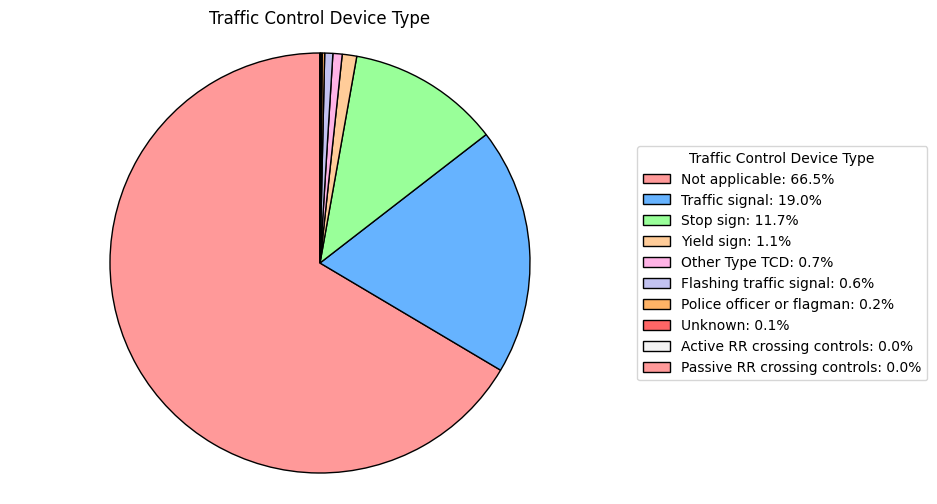

In [ ]:
import matplotlib.pyplot as plt

# Define valid values for each column
valid_collision_type = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
valid_relation_to_road = [1, 2, 3, 4, 5, 6, 7, 9]
valid_intersect_type = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
valid_tcd_type = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# Labels for each column
collision_type_labels = ['Non collision', 'Rear-end', 'Head-on', 'Rear-to-rear (Backing)', 'Angle',
                         'Sideswipe (same dir.)', 'Sideswipe (Opposite dir.)', 'Hit fixed object',
                         'Hit pedestrian', 'Other or Unknown']
relation_to_road_labels = ['On roadway', 'Shoulder', 'Median', 'Roadside (off trafficway; on vehicle area)',
                           'Outside trafficway (in area not meant for vehicles)', 'In parking lane',
                           'Gore (intersection of ramp and highway)', 'Unknown']
intersect_type_labels = ['Mid-block', 'Four way intersection', '"T" intersection', '"Y" intersection',
                         'Traffic circle or Round About', 'Multi-leg intersection', 'On ramp', 'Off ramp',
                         'Crossover', 'Railroad crossing', 'Other', 'Unknown']
tcd_type_labels = ['Not applicable', 'Flashing traffic signal', 'Traffic signal', 'Stop sign', 'Yield sign',
                   'Active RR crossing controls', 'Passive RR crossing controls', 'Police officer or flagman',
                   'Other Type TCD', 'Unknown']

# Function to plot pie chart
def plot_pie(column, title, labels, valid_values, colors=None):
    plt.figure(figsize=(8, 6))

    # Filter the data to keep only valid values
    filtered_data = df[df[column].isin(valid_values)]

    # Count the occurrences of each valid value
    value_counts = filtered_data[column].value_counts()

    # Map valid values to their corresponding labels and ensure alignment
    aligned_labels = [labels[valid_values.index(value)] for value in value_counts.index if value in valid_values]

    # Plot pie chart
    wedges, texts = plt.pie(
        value_counts,
        startangle=90,
        colors=colors,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1},
        pctdistance=0.85
    )

    # Title and legend
    plt.title(title)
    plt.axis('equal')  # Equal aspect ratio ensures the pie is drawn as a circle

    # Add a legend with percentages and labels
    legend_labels = [f'{label}: {percent:.1f}%' for label, percent in zip(aligned_labels, value_counts / value_counts.sum() * 100)]
    plt.legend(wedges, legend_labels, title=title, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

# Plotting pie charts for COLLISION_TYPE, RELATION_TO_ROAD, INTERSECT_TYPE, and TCD_TYPE
plot_pie("COLLISION_TYPE", "Collision Type", collision_type_labels, valid_collision_type, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666','#f2f2f2','#c2f0c2'])
plot_pie("RELATION_TO_ROAD", "Relation to Road", relation_to_road_labels, valid_relation_to_road, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666'])
plot_pie("INTERSECT_TYPE", "Intersection Type", intersect_type_labels, valid_intersect_type, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666','#f2f2f2','#c2f0c2','#ff9999','#c2c2c2'])
plot_pie("TCD_TYPE", "Traffic Control Device Type", tcd_type_labels, valid_tcd_type, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666','#f2f2f2'])


## Counts of Vehicle Types Plots

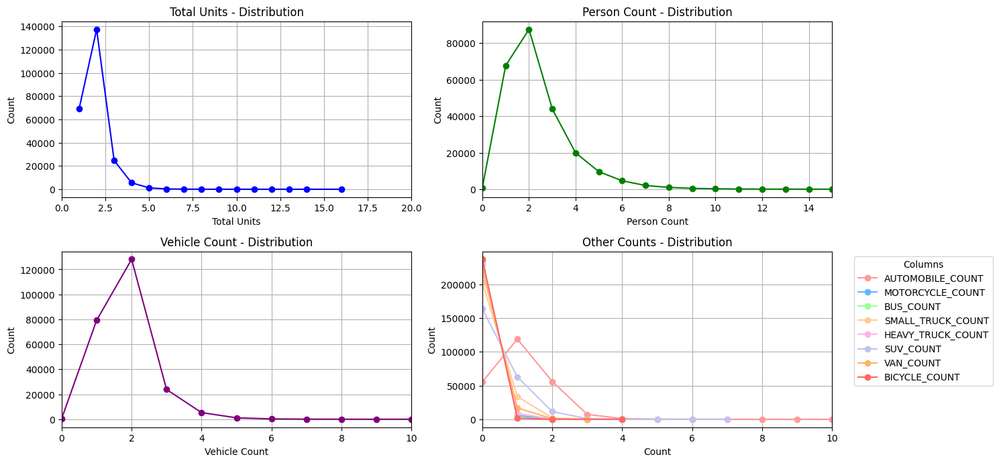

In [ ]:
# Creating the plots
plt.figure(figsize=(15, 10))

# Plot 1: TOTAL_UNITS distribution
plt.subplot(3, 2, 1)
total_units_counts = df["TOTAL_UNITS"].value_counts().sort_index()
plt.plot(total_units_counts.index, total_units_counts.values, marker='o', color='blue', label='Total Units')
plt.title("Total Units - Distribution")
plt.xlabel("Total Units")
plt.ylabel("Count")
plt.xlim(0, 20)  # Shrink x-axis to a reasonable range
plt.grid(True)

# Plot 2: PERSON_COUNT distribution
plt.subplot(3, 2, 2)
person_count_counts = df["PERSON_COUNT"].value_counts().sort_index()
plt.plot(person_count_counts.index, person_count_counts.values, marker='o', color='green', label='Person Count')
plt.title("Person Count - Distribution")
plt.xlabel("Person Count")
plt.ylabel("Count")
plt.xlim(0, 15)  # Shrink x-axis to a reasonable range
plt.grid(True)

# Plot 3: VEHICLE_COUNT distribution
plt.subplot(3, 2, 3)
vehicle_count_counts = df["VEHICLE_COUNT"].value_counts().sort_index()
plt.plot(vehicle_count_counts.index, vehicle_count_counts.values, marker='o', color='purple', label='Vehicle Count')
plt.title("Vehicle Count - Distribution")
plt.xlabel("Vehicle Count")
plt.ylabel("Count")
plt.xlim(0, 10)  # Shrink x-axis to a reasonable range
plt.grid(True)

# Plot 4: Combined plot for all other counts
plt.subplot(3, 2, 4)
columns = [
    "AUTOMOBILE_COUNT", "MOTORCYCLE_COUNT", "BUS_COUNT",
    "SMALL_TRUCK_COUNT", "HEAVY_TRUCK_COUNT", "SUV_COUNT", "VAN_COUNT", "BICYCLE_COUNT"
]
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#ffb3e6','#c2c2f0','#ffb366','#ff6666','#f2f2f2','#c2f0c2']

for i, col in enumerate(columns):
    column_counts = df[col].value_counts().sort_index()
    plt.plot(column_counts.index, column_counts.values, marker='o', color=colors[i], label=col)

plt.title("Other Counts - Distribution")
plt.xlabel("Count")
plt.ylabel("Count")
plt.xlim(0, 10)  # Shrink x-axis to a reasonable range
plt.legend(title="Columns", bbox_to_anchor=(1.05, 1), loc="upper left")  # Legend outside the plot
plt.grid(True)

# Adjust layout and display
plt.tight_layout()
plt.show()

## Injuries and Death Distributions

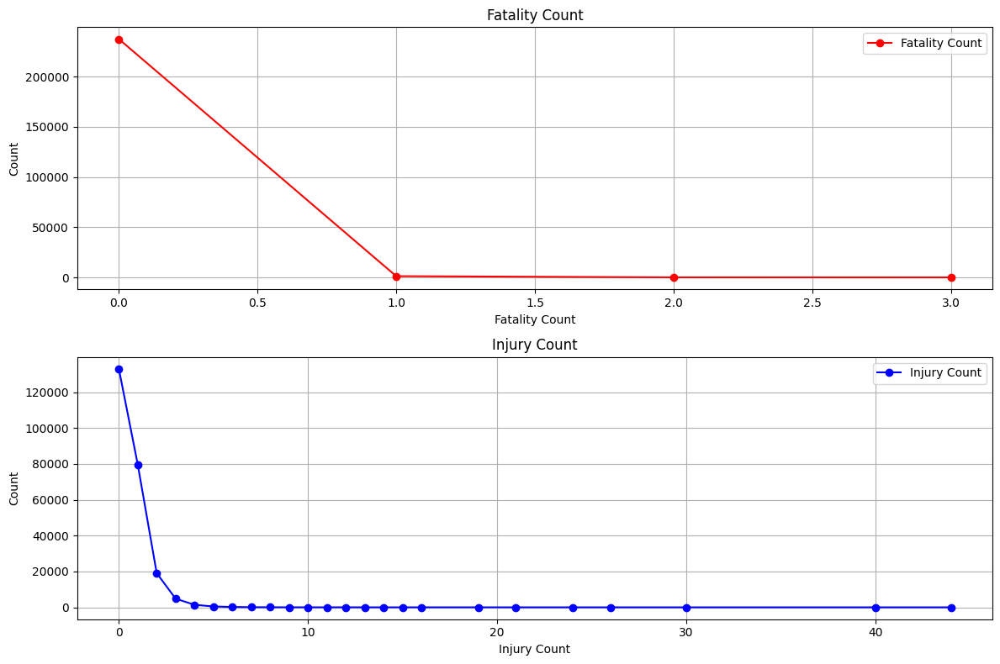

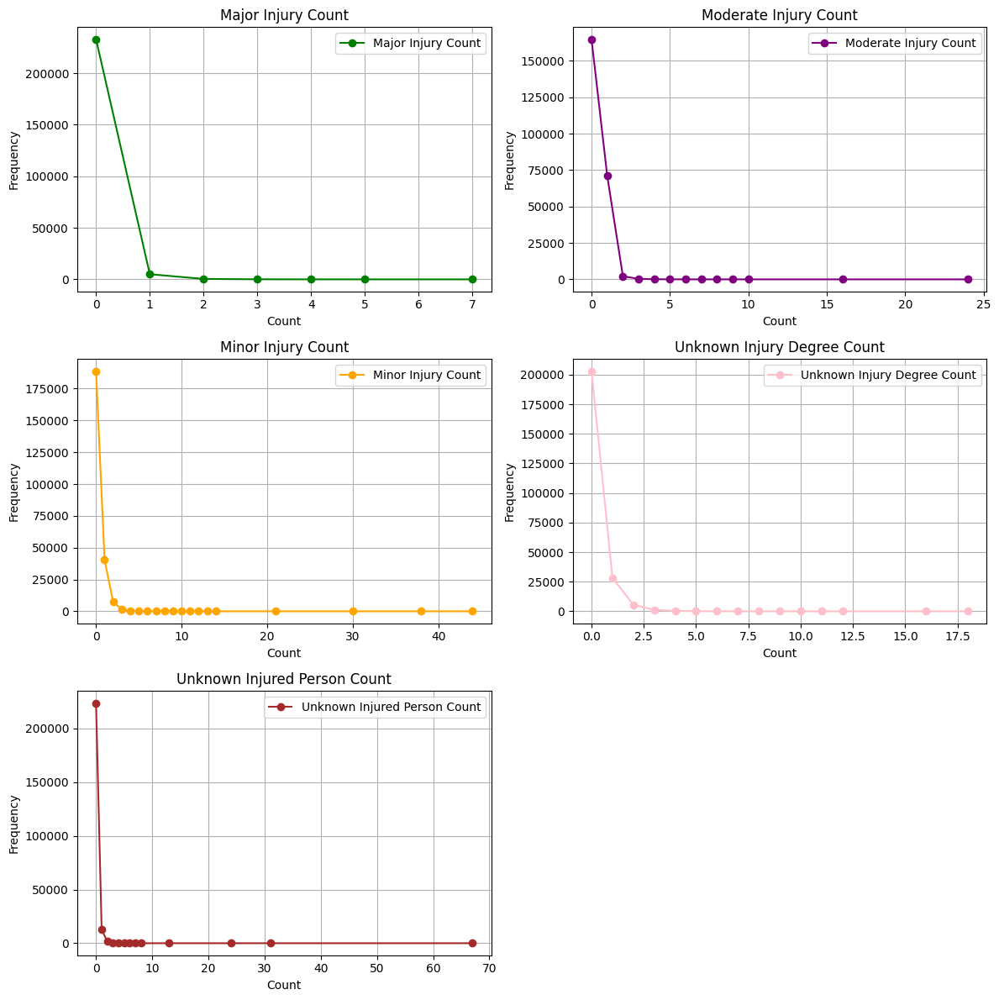

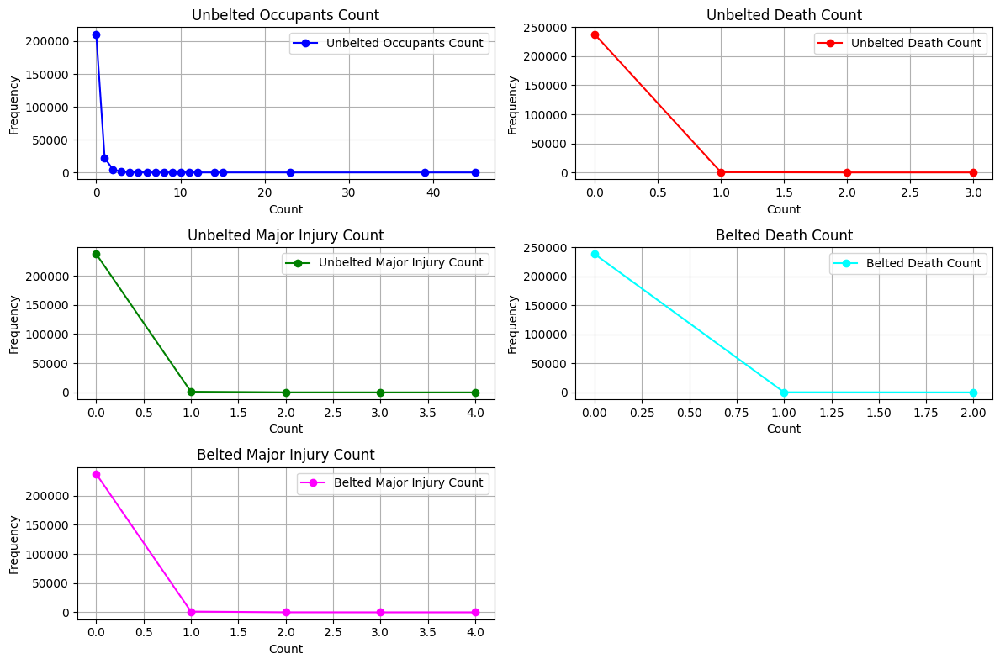

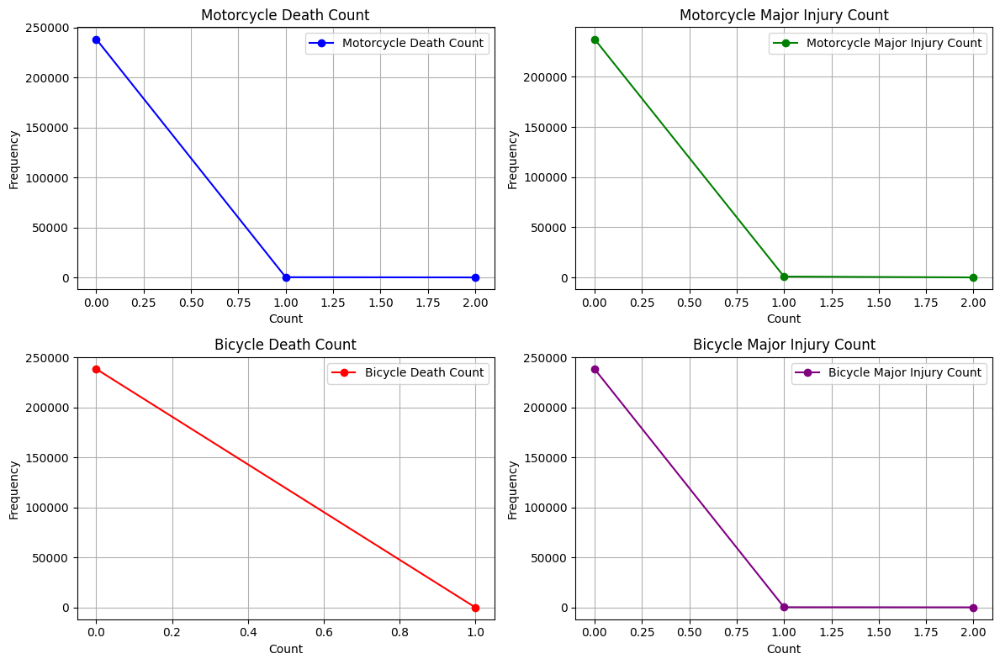

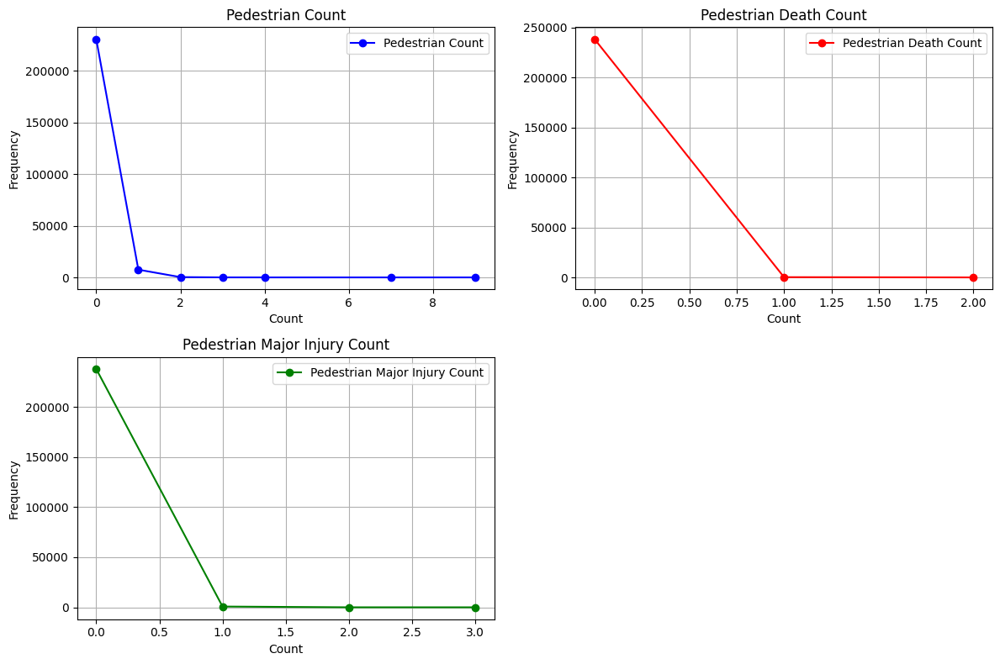

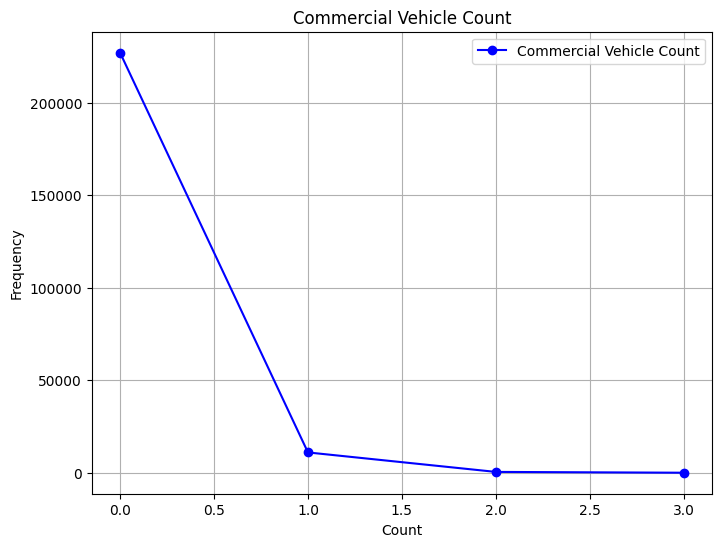

In [ ]:
# Group 1: Fatality and Injury Counts
plt.figure(figsize=(12, 8))

# 1. Fatality Count
plt.subplot(2, 1, 1)
fatal_count = df['FATAL_COUNT'].value_counts().sort_index()
plt.plot(fatal_count.index, fatal_count.values, label="Fatality Count", marker='o', linestyle='-', color='red')
plt.title("Fatality Count")
plt.xlabel('Fatality Count')
plt.ylabel('Count')
plt.legend()
plt.grid(True)

# 2. Injury Count
plt.subplot(2, 1, 2)
injury_count = df['INJURY_COUNT'].value_counts().sort_index()
plt.plot(injury_count.index, injury_count.values, label="Injury Count", marker='o', linestyle='-', color='blue')
plt.title("Injury Count")
plt.xlabel('Injury Count')
plt.ylabel('Count')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Group 2: Other Injury Counts
plt.figure(figsize=(12, 12))

columns = ['MAJ_INJ_COUNT', 'MOD_INJ_COUNT', 'MIN_INJ_COUNT', 'UNK_INJ_DEG_COUNT', 'UNK_INJ_PER_COUNT']
colors = ['green', 'purple', 'orange', 'pink', 'brown']
titles = ['Major Injury Count', 'Moderate Injury Count', 'Minor Injury Count',
          'Unknown Injury Degree Count', 'Unknown Injured Person Count']

for i, (col, color, title) in enumerate(zip(columns, colors, titles), 1):
    plt.subplot(3, 2, i)
    counts = df[col].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', linestyle='-', color=color, label=title)
    plt.title(title)
    plt.xlabel('Count')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# Group 3: Unbelted and Belted Occupants
plt.figure(figsize=(12, 8))

columns = ['UNBELTED_OCC_COUNT', 'UNB_DEATH_COUNT', 'UNB_MAJ_INJ_COUNT', 'BELTED_DEATH_COUNT', 'BELTED_MAJ_INJ_COUNT']
colors = ['blue', 'red', 'green', 'cyan', 'magenta']
titles = ['Unbelted Occupants Count', 'Unbelted Death Count', 'Unbelted Major Injury Count',
          'Belted Death Count', 'Belted Major Injury Count']

for i, (col, color, title) in enumerate(zip(columns, colors, titles), 1):
    plt.subplot(3, 2, i)
    counts = df[col].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', linestyle='-', color=color, label=title)
    plt.title(title)
    plt.xlabel('Count')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# Group 4: Vehicle and Bicycle-related Counts
plt.figure(figsize=(12, 8))

columns = ['MCYCLE_DEATH_COUNT', 'MCYCLE_MAJ_INJ_COUNT', 'BICYCLE_DEATH_COUNT', 'BICYCLE_MAJ_INJ_COUNT']
colors = ['blue', 'green', 'red', 'purple']
titles = ['Motorcycle Death Count', 'Motorcycle Major Injury Count', 'Bicycle Death Count',
          'Bicycle Major Injury Count']

for i, (col, color, title) in enumerate(zip(columns, colors, titles), 1):
    plt.subplot(2, 2, i)
    counts = df[col].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', linestyle='-', color=color, label=title)
    plt.title(title)
    plt.xlabel('Count')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# Group 5: Pedestrian-related Counts
plt.figure(figsize=(12, 8))

columns = ['PED_COUNT', 'PED_DEATH_COUNT', 'PED_MAJ_INJ_COUNT']
colors = ['blue', 'red', 'green']
titles = ['Pedestrian Count', 'Pedestrian Death Count', 'Pedestrian Major Injury Count']

for i, (col, color, title) in enumerate(zip(columns, colors, titles), 1):
    plt.subplot(2, 2, i)
    counts = df[col].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', linestyle='-', color=color, label=title)
    plt.title(title)
    plt.xlabel('Count')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# Group 6: Commercial Vehicle Count
plt.figure(figsize=(8, 6))
comm_veh_count = df['COMM_VEH_COUNT'].value_counts().sort_index()
plt.plot(comm_veh_count.index, comm_veh_count.values, label="Commercial Vehicle Count", marker='o', linestyle='-', color='blue')
plt.title("Commercial Vehicle Count")
plt.xlabel('Count')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

## Severity of Accident

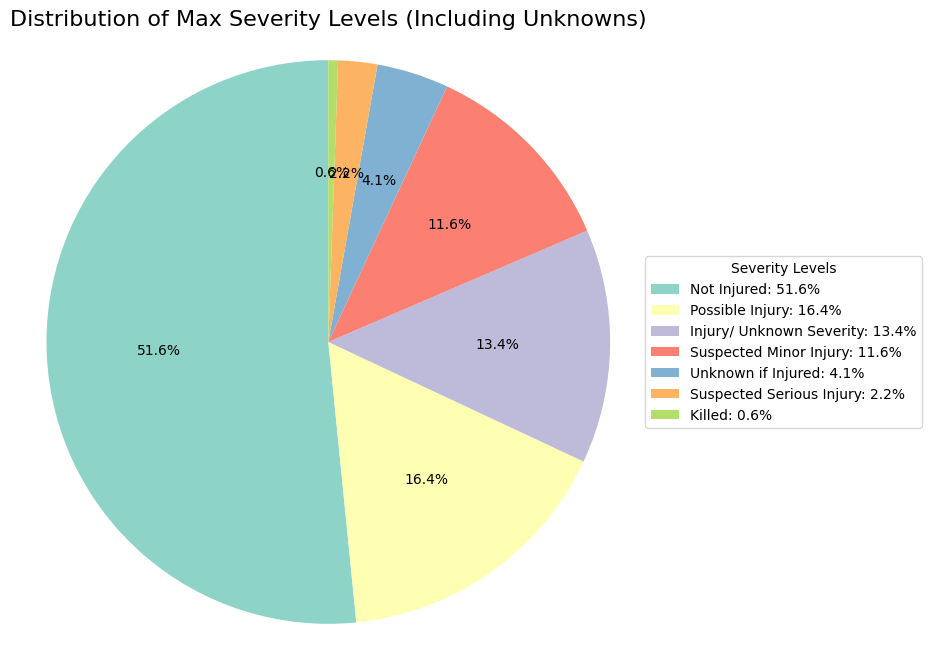

<ipython-input-49-d6f2413e4cda>:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


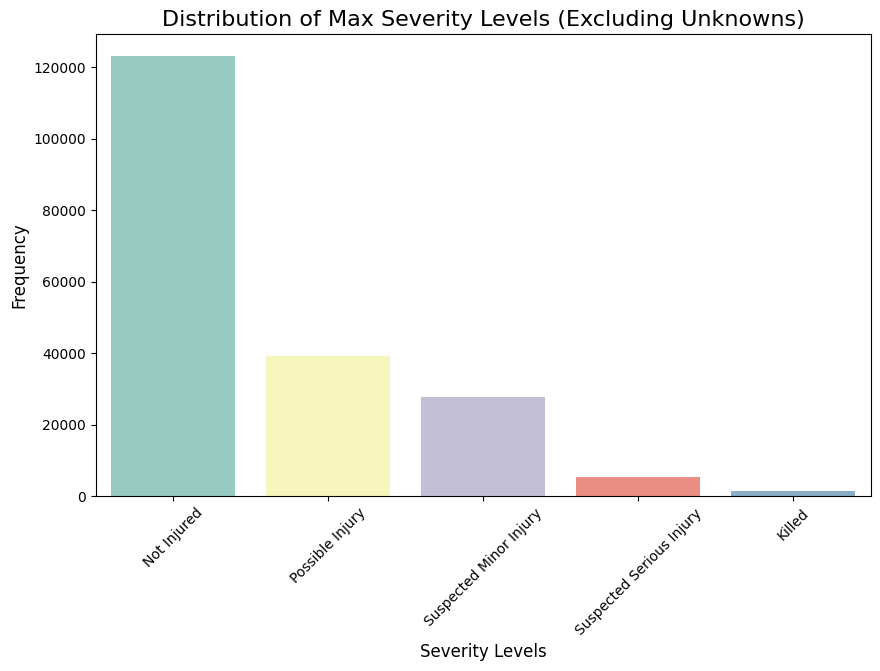

In [ ]:
# Logical severity order (including unknowns for pie chart)
severity_order_pie = {
    0: "Not Injured",
    4: "Possible Injury",
    3: "Suspected Minor Injury",
    2: "Suspected Serious Injury",
    1: "Killed",
    8: "Injury/ Unknown Severity",  # Including unknown severity
    9: "Unknown if Injured"          # Including unknown severity
}

# Map severity levels to their descriptions for both Pie and Distribution Plot
df["Severity_Label"] = df["MAX_SEVERITY_LEVEL"].map(severity_order_pie)

# Plotting the Pie chart with percentages in the legend
plt.figure(figsize=(8, 8))
severity_counts = df["Severity_Label"].value_counts()

# Plot pie chart without labels inside the chart
plt.pie(
    severity_counts,
    labels=None,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3", len(severity_counts))
)

# Title and adjustments
plt.title("Distribution of Max Severity Levels (Including Unknowns)", fontsize=16)
plt.axis('equal')  # Equal aspect ratio ensures that pie chart is circular

# Create legend with severity names and percentages
legend_labels = [
    f"{label}: {percent:.1f}%" for label, percent in zip(
        severity_counts.index, severity_counts / severity_counts.sum() * 100
    )
]
plt.legend(legend_labels, loc="center left", bbox_to_anchor=(1, 0.5), title="Severity Levels")

# Show pie chart
plt.show()

# Plotting Distribution plot for Severity Levels excluding Unknowns (severity 8 and 9)
filtered_severity = df[~df['MAX_SEVERITY_LEVEL'].isin([8, 9])]  # Exclude 8 and 9 (Unknown/Unknown if Injured)

# Plot Distribution plot for the severity levels (excluding Unknowns)
plt.figure(figsize=(10, 6))
sns.countplot(
    x='Severity_Label',
    data=filtered_severity,
    order=["Not Injured", "Possible Injury", "Suspected Minor Injury",
           "Suspected Serious Injury", "Killed"],
    palette="Set3"
)

# Title and adjustments
plt.title("Distribution of Max Severity Levels (Excluding Unknowns)", fontsize=16)
plt.xlabel("Severity Levels", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.xticks(rotation=45)  # Rotate labels for better visibility

# Show Distribution plot
plt.show()

## Driver Age

<ipython-input-50-5963d4deb3d2>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_group_sums.index, y=age_group_sums.values, palette="viridis")


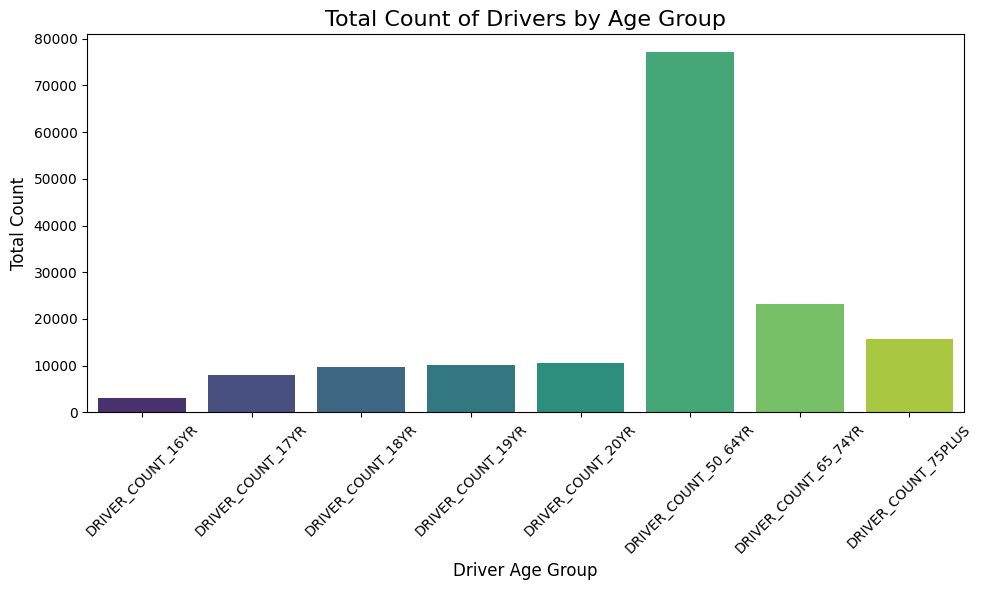

In [ ]:
# List of relevant columns
columns = [
    "DRIVER_COUNT_16YR",
    "DRIVER_COUNT_17YR",
    "DRIVER_COUNT_18YR",
    "DRIVER_COUNT_19YR",
    "DRIVER_COUNT_20YR",
    "DRIVER_COUNT_50_64YR",
    "DRIVER_COUNT_65_74YR",
    "DRIVER_COUNT_75PLUS"
]

# Calculate the sum of each driver age group
age_group_sums = df[columns].sum()

# Create a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=age_group_sums.index, y=age_group_sums.values, palette="viridis")

# Add labels and title
plt.title("Total Count of Drivers by Age Group", fontsize=16)
plt.xlabel("Driver Age Group", fontsize=12)
plt.ylabel("Total Count", fontsize=12)
plt.xticks(rotation=45)  # Rotate x-axis labels for better visibility

# Show plot
plt.tight_layout()
plt.show()

## Speed Limit

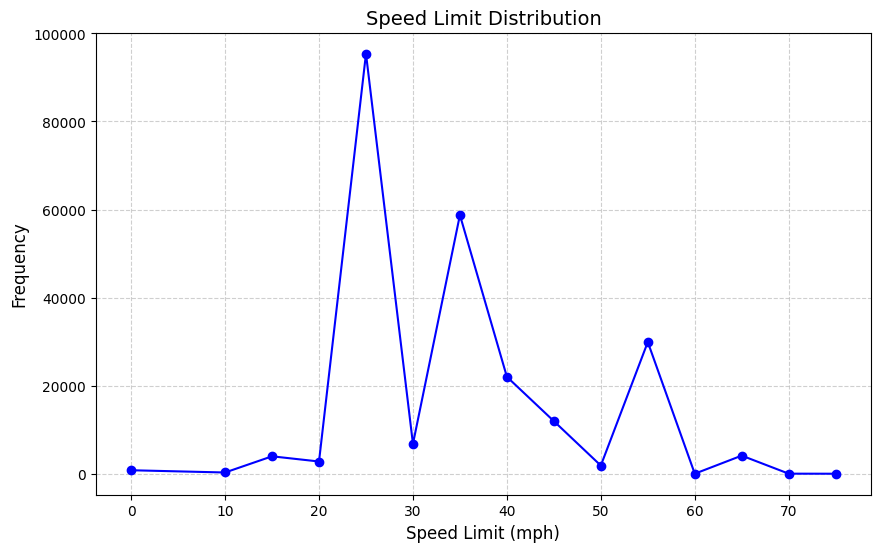

In [ ]:
# Calculate frequency of each unique speed limit
speed_limit_counts = df['SPEED_LIMIT'].value_counts().sort_index()

# Plot distribution
plt.figure(figsize=(10, 6))
plt.plot(speed_limit_counts.index, speed_limit_counts.values, marker='o', linestyle='-', color='b')
plt.title("Speed Limit Distribution", fontsize=14)
plt.xlabel("Speed Limit (mph)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Show the plot
plt.show()

## Box Plot: Injury Count vs. Weather Conditions

<ipython-input-56-63c51bd9fb0d>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="WEATHER", y="INJURY_COUNT", palette="Set3")


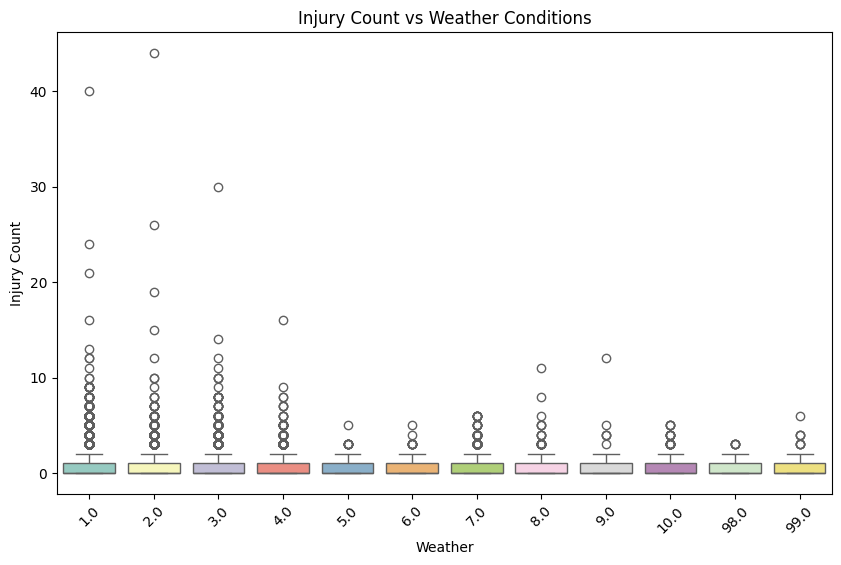

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="WEATHER", y="INJURY_COUNT", palette="Set3")
plt.title("Injury Count vs Weather Conditions")
plt.xlabel("Weather")
plt.ylabel("Injury Count")
plt.xticks(rotation=45)
plt.show()

## Heatmap: Correlation of Features for Classification

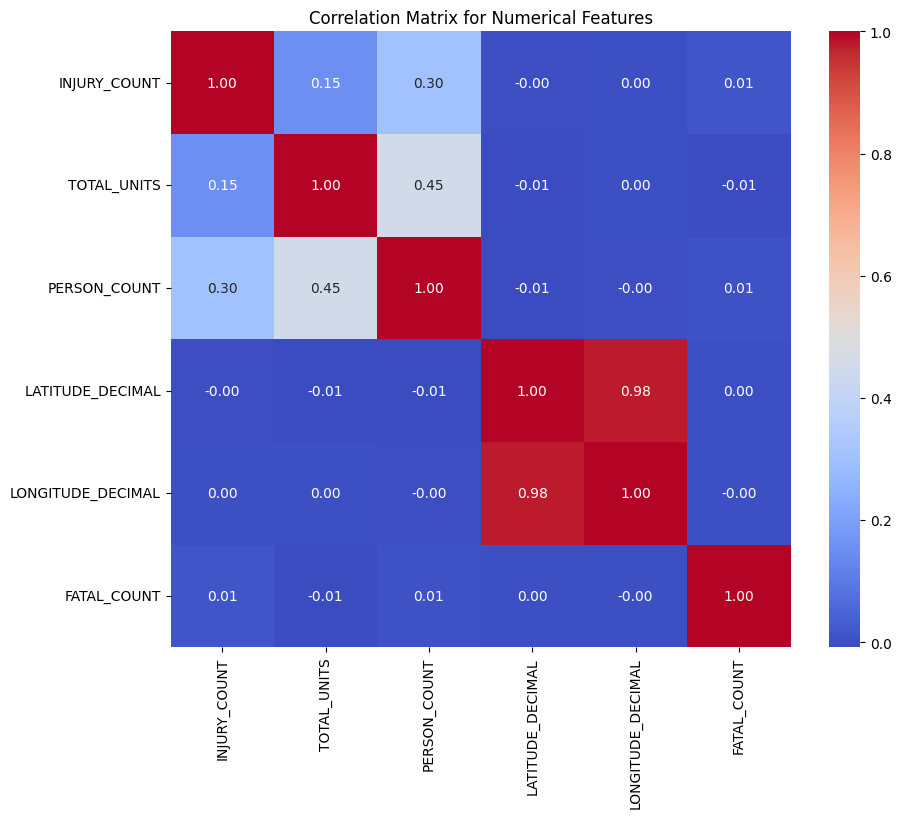

In [26]:
correlation_matrix = df[['INJURY_COUNT', 'TOTAL_UNITS', 'PERSON_COUNT', 'LATITUDE_DECIMAL', 'LONGITUDE_DECIMAL', 'FATAL_COUNT']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix for Numerical Features")
plt.show()

## KDE Plots

<ipython-input-27-60dac32221a9>:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['INJURY_COUNT'].dropna(), shade=True, color='skyblue')


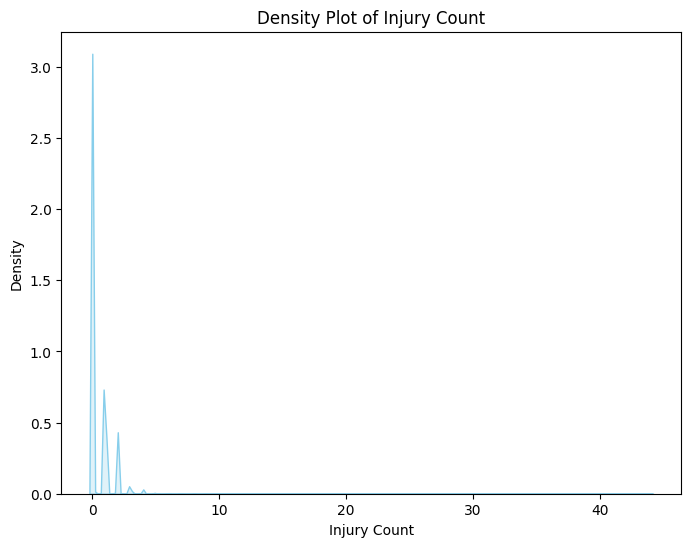

<ipython-input-27-60dac32221a9>:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['TOTAL_UNITS'].dropna(), shade=True, color='lightgreen')


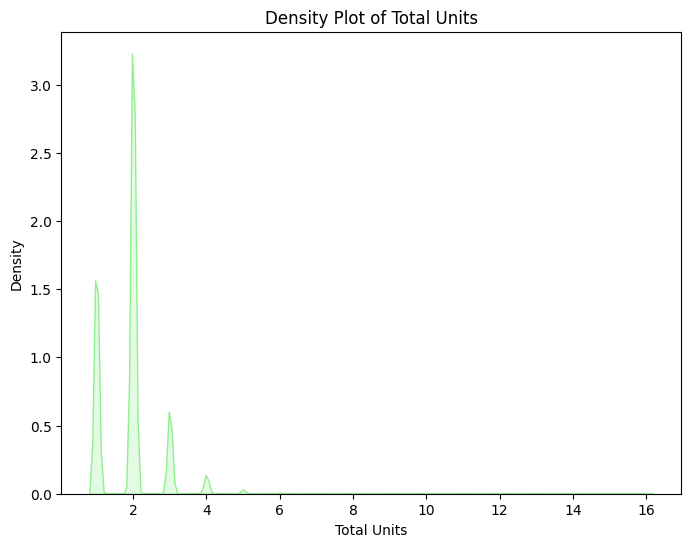

<ipython-input-27-60dac32221a9>:22: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['PERSON_COUNT'].dropna(), shade=True, color='orange')


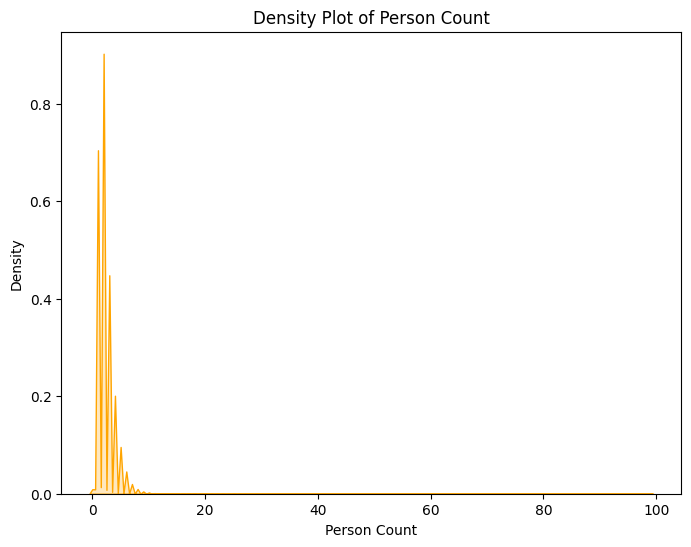

<ipython-input-27-60dac32221a9>:30: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['LATITUDE_DECIMAL'].dropna(), shade=True, color='purple')


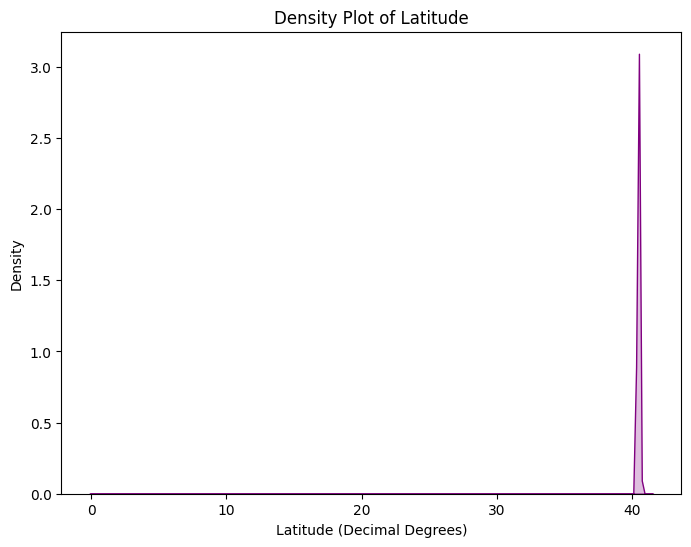

<ipython-input-27-60dac32221a9>:38: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['LONGITUDE_DECIMAL'].dropna(), shade=True, color='red')


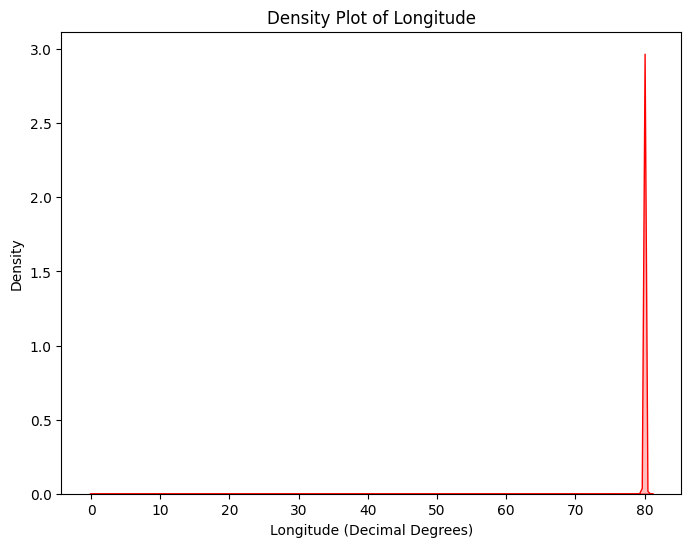

<ipython-input-27-60dac32221a9>:46: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['HOUR_OF_DAY'].dropna(), shade=True, color='teal')


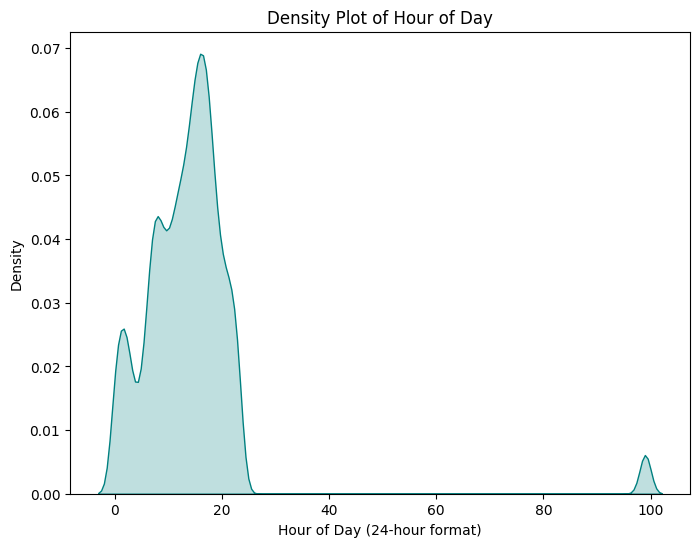

<ipython-input-27-60dac32221a9>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='MAX_SEVERITY_LEVEL', palette="viridis")


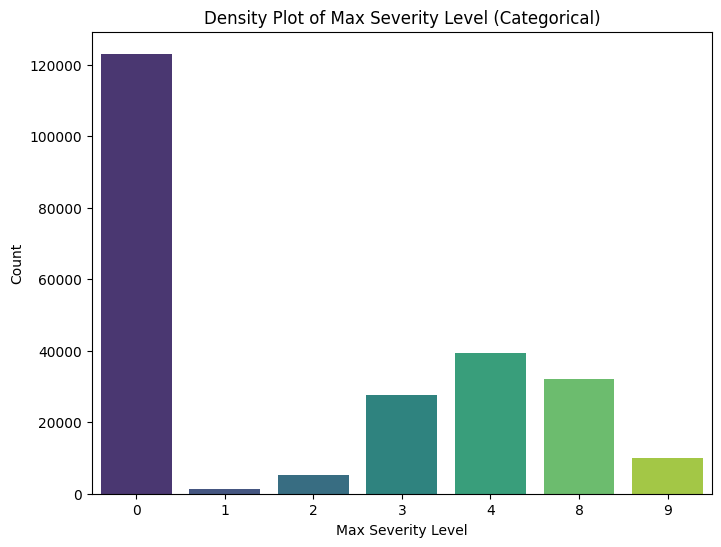

<ipython-input-27-60dac32221a9>:63: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['TIME_OF_DAY_MINUTES'].dropna(), shade=True, color='cyan')


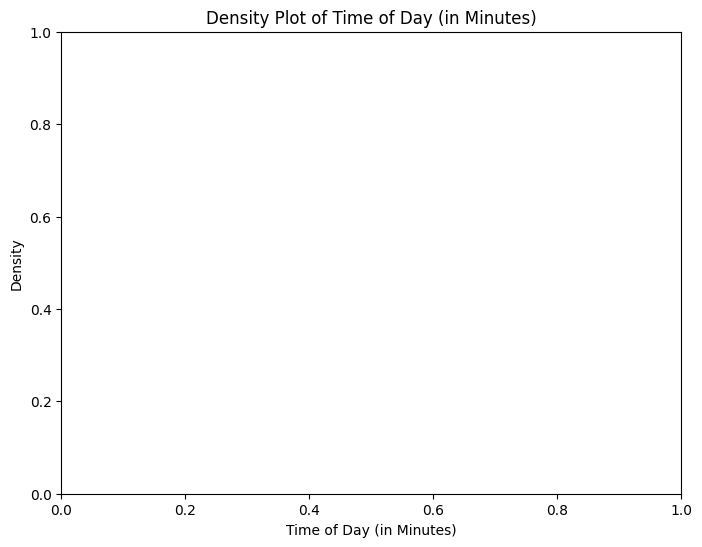

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Density Plot for Injury Count (target variable)
plt.figure(figsize=(8, 6))
sns.kdeplot(df['INJURY_COUNT'].dropna(), shade=True, color='skyblue')
plt.title("Density Plot of Injury Count")
plt.xlabel("Injury Count")
plt.ylabel("Density")
plt.show()

# 2. Density Plot for Total Units involved in accident
plt.figure(figsize=(8, 6))
sns.kdeplot(df['TOTAL_UNITS'].dropna(), shade=True, color='lightgreen')
plt.title("Density Plot of Total Units")
plt.xlabel("Total Units")
plt.ylabel("Density")
plt.show()

# 3. Density Plot for Person Count involved in accident
plt.figure(figsize=(8, 6))
sns.kdeplot(df['PERSON_COUNT'].dropna(), shade=True, color='orange')
plt.title("Density Plot of Person Count")
plt.xlabel("Person Count")
plt.ylabel("Density")
plt.show()

# 4. Density Plot for Latitude (in decimal format)
plt.figure(figsize=(8, 6))
sns.kdeplot(df['LATITUDE_DECIMAL'].dropna(), shade=True, color='purple')
plt.title("Density Plot of Latitude")
plt.xlabel("Latitude (Decimal Degrees)")
plt.ylabel("Density")
plt.show()

# 5. Density Plot for Longitude (in decimal format)
plt.figure(figsize=(8, 6))
sns.kdeplot(df['LONGITUDE_DECIMAL'].dropna(), shade=True, color='red')
plt.title("Density Plot of Longitude")
plt.xlabel("Longitude (Decimal Degrees)")
plt.ylabel("Density")
plt.show()

# 6. Density Plot for Hour of Day (24-hour format)
plt.figure(figsize=(8, 6))
sns.kdeplot(df['HOUR_OF_DAY'].dropna(), shade=True, color='teal')
plt.title("Density Plot of Hour of Day")
plt.xlabel("Hour of Day (24-hour format)")
plt.ylabel("Density")
plt.show()

# 7. Density Plot for Max Severity Level (categorical variable)
# Since it's categorical, we can only visualize counts. We'll skip the KDE here and use countplot.
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='MAX_SEVERITY_LEVEL', palette="viridis")
plt.title("Density Plot of Max Severity Level (Categorical)")
plt.xlabel("Max Severity Level")
plt.ylabel("Count")
plt.show()

# 8. Density Plot for Time of Day (converted to minutes)
plt.figure(figsize=(8, 6))
sns.kdeplot(df['TIME_OF_DAY_MINUTES'].dropna(), shade=True, color='cyan')
plt.title("Density Plot of Time of Day (in Minutes)")
plt.xlabel("Time of Day (in Minutes)")
plt.ylabel("Density")
plt.show()


## Violin Plots

<ipython-input-28-a2c65b79a120>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="INJURY_COUNT", palette="Set2")


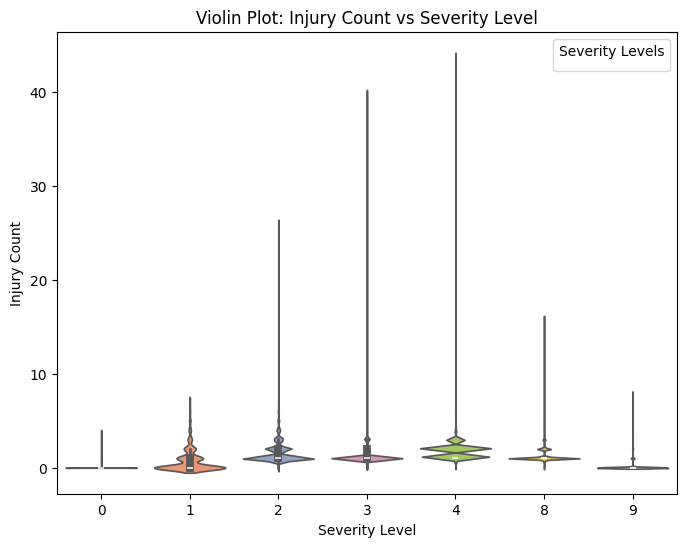

<ipython-input-28-a2c65b79a120>:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="TOTAL_UNITS", palette="Set3")


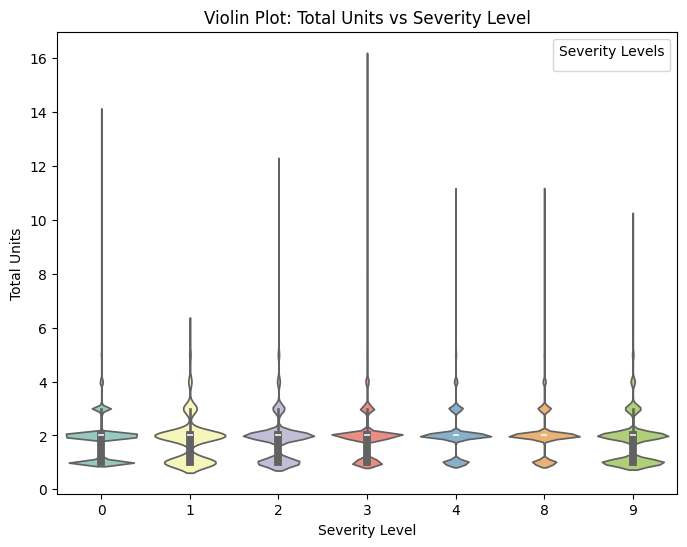

<ipython-input-28-a2c65b79a120>:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="PERSON_COUNT", palette="Set1")


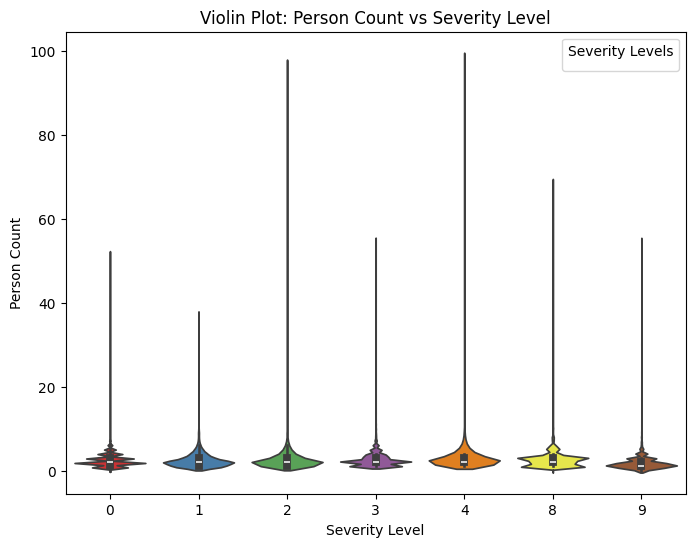

<ipython-input-28-a2c65b79a120>:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="LATITUDE_DECIMAL", palette="Set2")


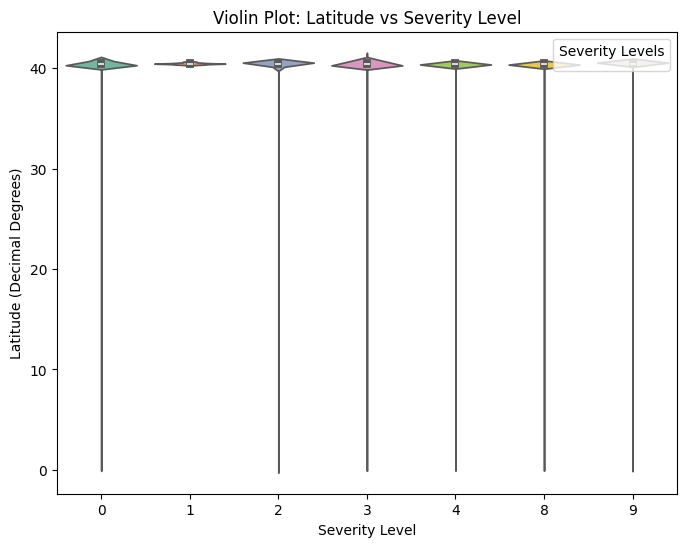

<ipython-input-28-a2c65b79a120>:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="LONGITUDE_DECIMAL", palette="Set3")


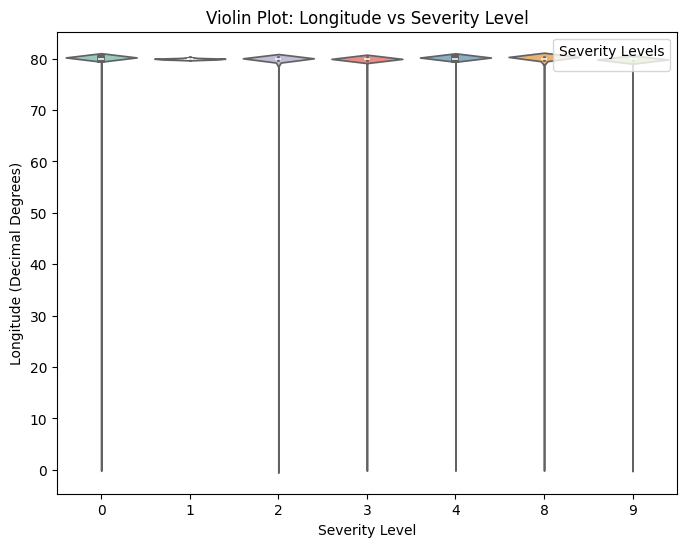

<ipython-input-28-a2c65b79a120>:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="HOUR_OF_DAY", palette="viridis")


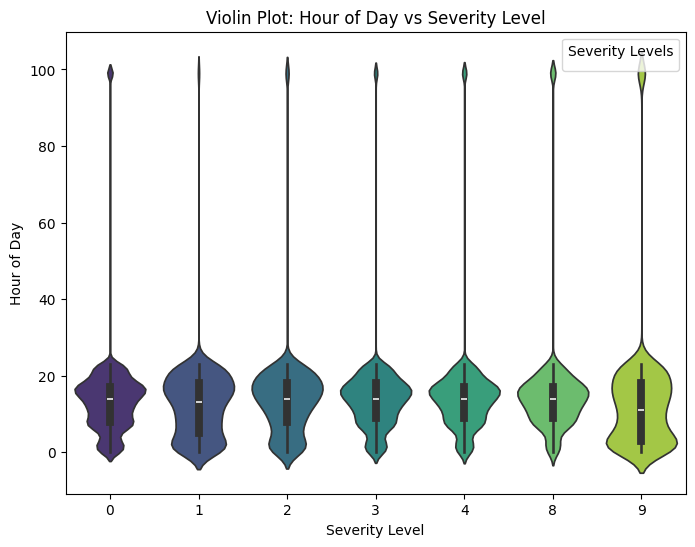

<ipython-input-28-a2c65b79a120>:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="TIME_OF_DAY_MINUTES", palette="coolwarm")


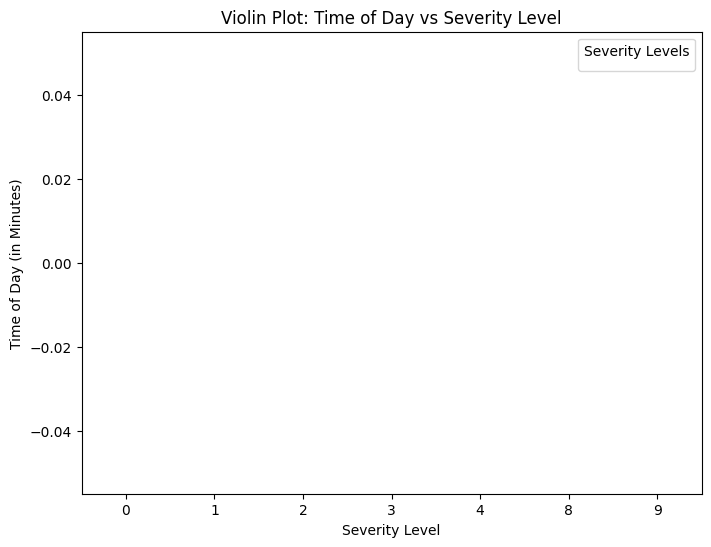

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Severity Level Descriptions
severity_labels = {
    0: "Not Injured",
    1: "Killed",
    2: "Suspected Serious Injury",
    3: "Suspected Minor Injury",
    4: "Possible Injury",
    8: "Injury/Unknown Severity",
    9: "Unknown if Injured"
}

# 1. Violin Plot for Injury Count vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="INJURY_COUNT", palette="Set2")
plt.title("Violin Plot: Injury Count vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Injury Count")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 2. Violin Plot for Total Units vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="TOTAL_UNITS", palette="Set3")
plt.title("Violin Plot: Total Units vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Total Units")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 3. Violin Plot for Person Count vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="PERSON_COUNT", palette="Set1")
plt.title("Violin Plot: Person Count vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Person Count")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 4. Violin Plot for Latitude vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="LATITUDE_DECIMAL", palette="Set2")
plt.title("Violin Plot: Latitude vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Latitude (Decimal Degrees)")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 5. Violin Plot for Longitude vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="LONGITUDE_DECIMAL", palette="Set3")
plt.title("Violin Plot: Longitude vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Longitude (Decimal Degrees)")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 6. Violin Plot for Hour of Day vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="HOUR_OF_DAY", palette="viridis")
plt.title("Violin Plot: Hour of Day vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Hour of Day")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

# 7. Violin Plot for Time of Day (in minutes) vs Severity Level
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x="MAX_SEVERITY_LEVEL", y="TIME_OF_DAY_MINUTES", palette="coolwarm")
plt.title("Violin Plot: Time of Day vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Time of Day (in Minutes)")

# Adding Custom Legend for Severity Levels
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [severity_labels[int(label)] if label.isdigit() else label for label in labels]
plt.legend(handles, new_labels, title="Severity Levels", loc='upper right')

plt.show()

## Dot Plots

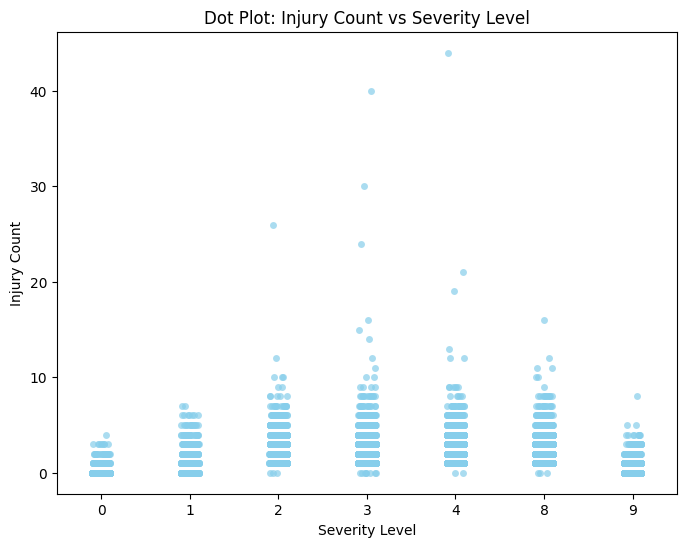

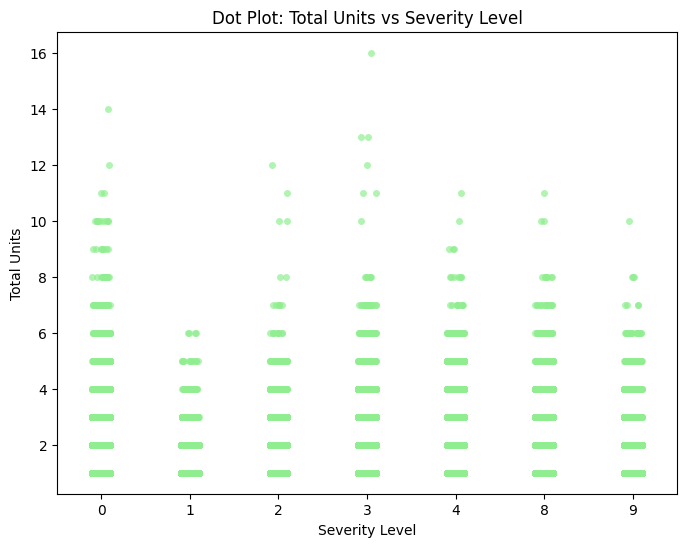

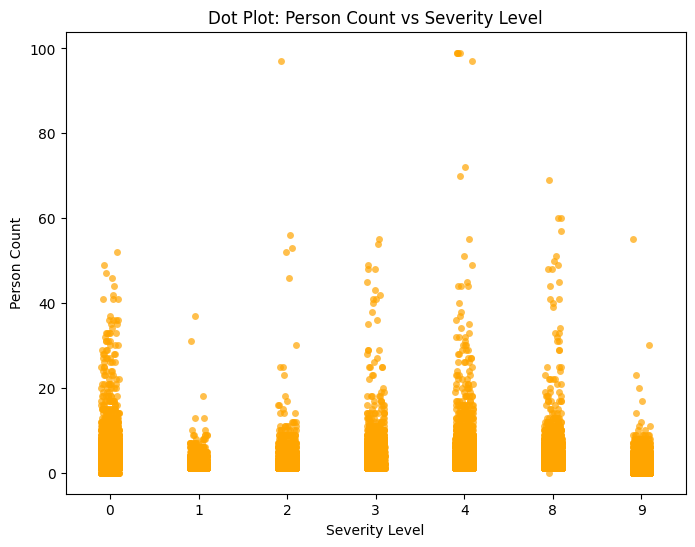

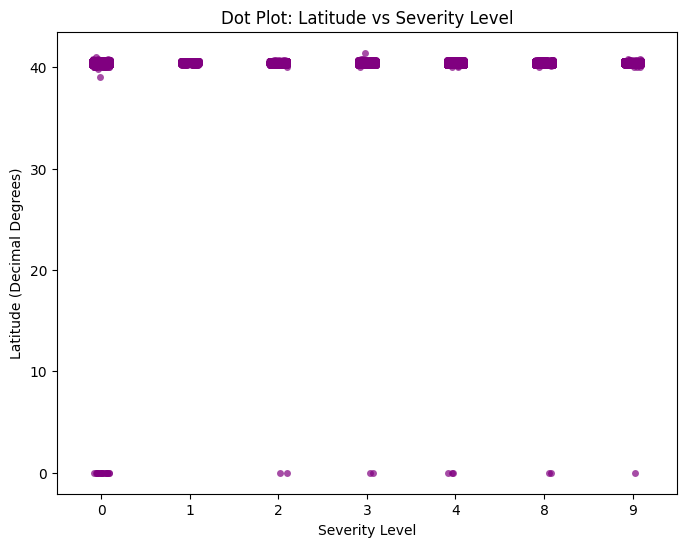

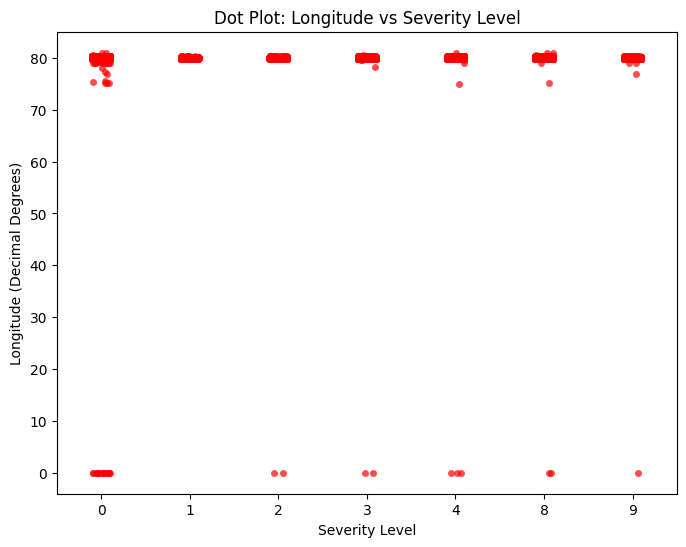

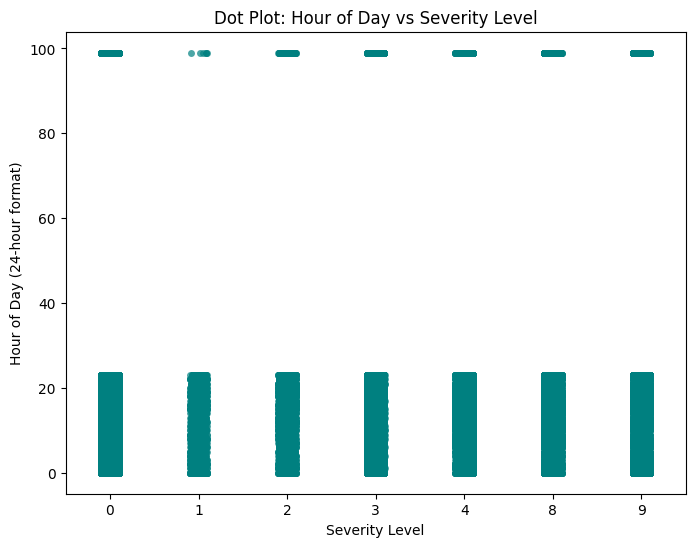

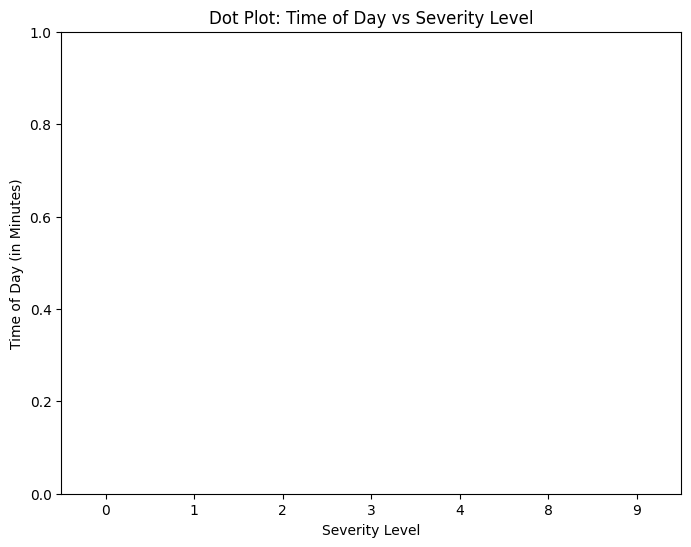

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dot Plot for Injury Count vs Severity Level
# Visualizing how injury count spreads across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="INJURY_COUNT", jitter=True, color='skyblue', alpha=0.7)
plt.title("Dot Plot: Injury Count vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Injury Count")
plt.show()

# 2. Dot Plot for Total Units vs Severity Level
# Visualizing how total units involved in accidents spread across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="TOTAL_UNITS", jitter=True, color='lightgreen', alpha=0.7)
plt.title("Dot Plot: Total Units vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Total Units")
plt.show()

# 3. Dot Plot for Person Count vs Severity Level
# Visualizing how the person count spreads across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="PERSON_COUNT", jitter=True, color='orange', alpha=0.7)
plt.title("Dot Plot: Person Count vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Person Count")
plt.show()

# 4. Dot Plot for Latitude vs Severity Level
# Visualizing how latitude values spread across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="LATITUDE_DECIMAL", jitter=True, color='purple', alpha=0.7)
plt.title("Dot Plot: Latitude vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Latitude (Decimal Degrees)")
plt.show()

# 5. Dot Plot for Longitude vs Severity Level
# Visualizing how longitude values spread across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="LONGITUDE_DECIMAL", jitter=True, color='red', alpha=0.7)
plt.title("Dot Plot: Longitude vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Longitude (Decimal Degrees)")
plt.show()

# 6. Dot Plot for Hour of Day vs Severity Level
# Visualizing how the hour of the day (24-hour format) spreads across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="HOUR_OF_DAY", jitter=True, color='teal', alpha=0.7)
plt.title("Dot Plot: Hour of Day vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Hour of Day (24-hour format)")
plt.show()

# 7. Dot Plot for Time of Day (in minutes) vs Severity Level
# Visualizing how the time of day (in minutes) spreads across different severity levels
plt.figure(figsize=(8, 6))
sns.stripplot(data=df, x="MAX_SEVERITY_LEVEL", y="TIME_OF_DAY_MINUTES", jitter=True, color='cyan', alpha=0.7)
plt.title("Dot Plot: Time of Day vs Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Time of Day (in Minutes)")
plt.show()


## QQ Plots

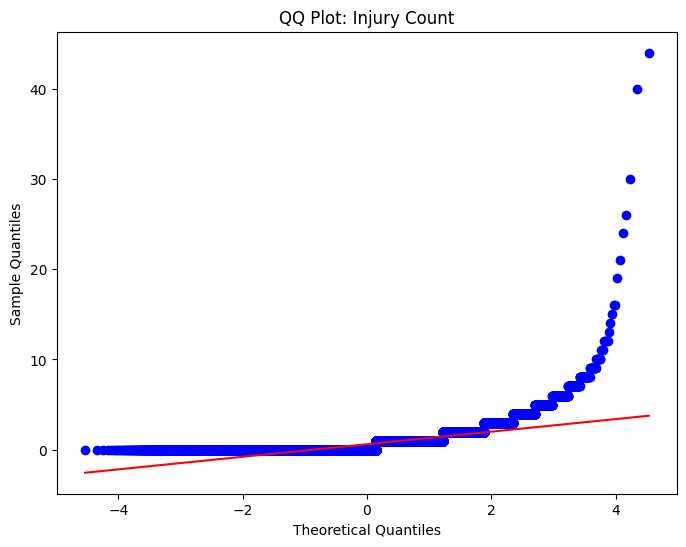

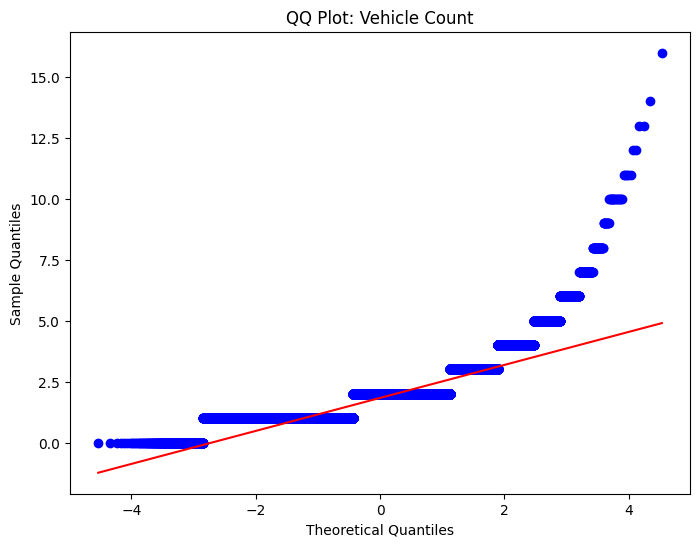

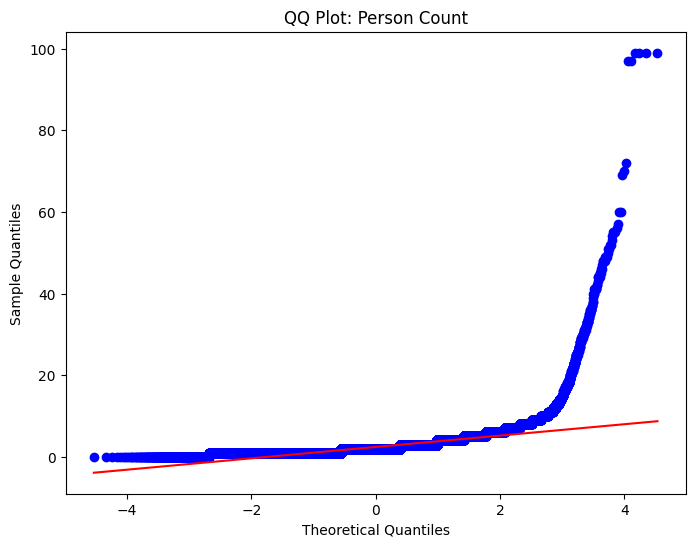

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

# 1. QQ Plot for Injury Count
plt.figure(figsize=(8, 6))
stats.probplot(df['INJURY_COUNT'].dropna(), dist="norm", plot=plt)
plt.title("QQ Plot: Injury Count")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

# 2. QQ Plot for Vehicle Count
plt.figure(figsize=(8, 6))
stats.probplot(df['VEHICLE_COUNT'].dropna(), dist="norm", plot=plt)
plt.title("QQ Plot: Vehicle Count")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

# 3. QQ Plot for Person Count
plt.figure(figsize=(8, 6))
stats.probplot(df['PERSON_COUNT'].dropna(), dist="norm", plot=plt)
plt.title("QQ Plot: Person Count")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

## Radar(Spider) Plot

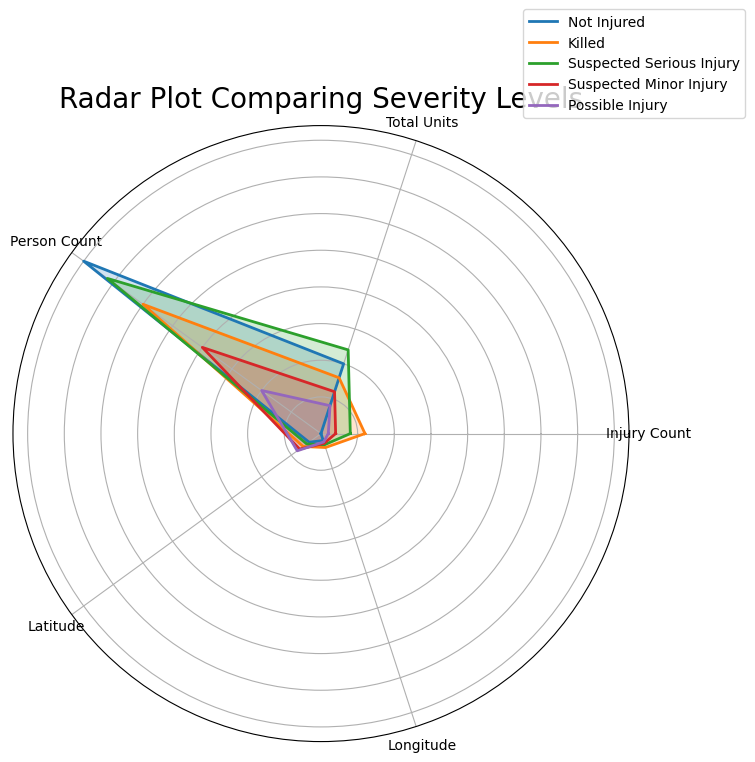

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Data for the Radar plot
labels = ["Injury Count", "Total Units", "Person Count", "Latitude", "Longitude"]
severity_levels = ['Not Injured', 'Killed', 'Suspected Serious Injury', 'Suspected Minor Injury', 'Possible Injury']

# Example data: Replace these with actual summary statistics
data = {
    "Not Injured": [0, 50, 200, 10, 5],
    "Killed": [30, 40, 150, 15, 10],
    "Suspected Serious Injury": [20, 60, 180, 12, 8],
    "Suspected Minor Injury": [10, 30, 100, 18, 7],
    "Possible Injury": [5, 20, 50, 20, 6],
}

# Function to create the radar plot
def radar_plot(data, labels, severity_levels):
    # Number of features
    num_vars = len(labels)

    # Create a 2D array for the plot
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

    # Make the plot circular
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    for level in severity_levels:
        stats = data[level]
        stats += stats[:1]  # Repeat the first value to close the circle
        ax.plot(angles, stats, label=level, linewidth=2, linestyle='solid')
        ax.fill(angles, stats, alpha=0.2)

    ax.set_yticklabels([])  # Remove the radial ticks
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)

    plt.title("Radar Plot Comparing Severity Levels", size=20)
    plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.2))
    plt.show()

# Calling the function to create the radar plot
radar_plot(data, labels, severity_levels)


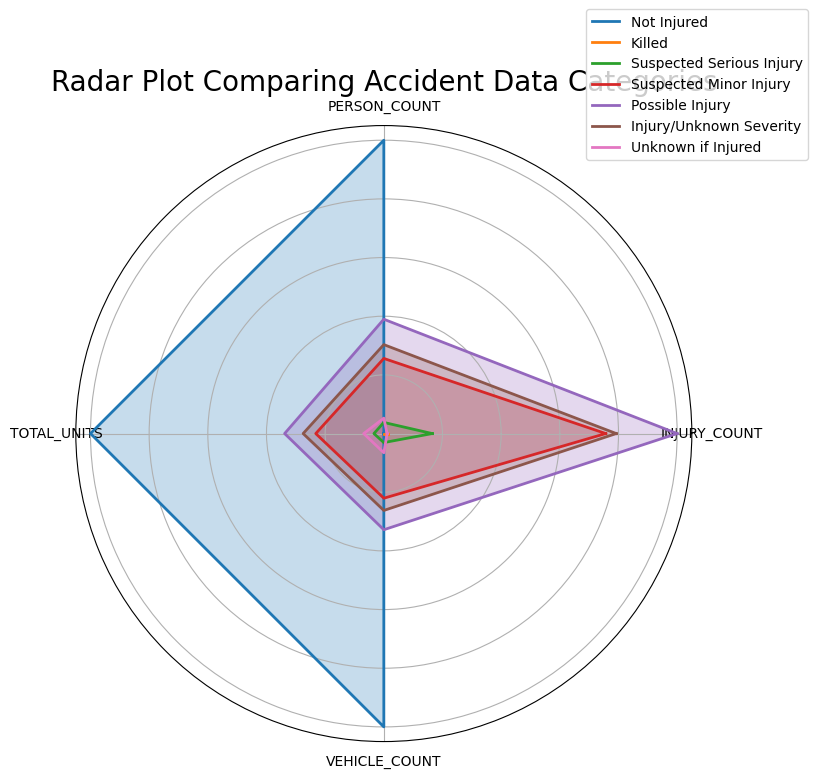

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the labels for the features you want to compare
labels = ['INJURY_COUNT', 'PERSON_COUNT', 'TOTAL_UNITS', 'VEHICLE_COUNT']

# Map the severity levels from encoded values to their descriptive names
severity_labels = {
    0: "Not Injured",
    1: "Killed",
    2: "Suspected Serious Injury",
    3: "Suspected Minor Injury",
    4: "Possible Injury",
    8: "Injury/Unknown Severity",
    9: "Unknown if Injured"
}

# Example: Group the data by encoded severity levels and sum the relevant columns
# (Assuming `df` is your DataFrame with the relevant columns)
grouped = df.groupby('MAX_SEVERITY_LEVEL')[labels].sum()

# Normalize the data (optional)
grouped_normalized = (grouped - grouped.min()) / (grouped.max() - grouped.min())  # Min-Max scaling

# Function to create the radar plot
def radar_plot(data, labels, severity_labels):
    # Number of variables (features)
    num_vars = len(labels)

    # Compute angle for each axis (evenly spaced around the circle)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

    # Close the circle by appending the first value to the end
    angles += angles[:1]

    # Set up the figure and axis
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Plot each category's data (severity levels)
    for level, stats in data.iterrows():
        # Append the first value to the end to close the loop
        stats_values = stats.tolist() + [stats.tolist()[0]]  # Add first value at the end to close the loop
        ax.plot(angles, stats_values, label=severity_labels.get(level, f"Severity {level}"), linewidth=2, linestyle='solid')
        ax.fill(angles, stats_values, alpha=0.25)

    # Set axis labels
    ax.set_yticklabels([])  # Remove radial ticks
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)

    # Title and legend
    plt.title("Radar Plot Comparing Accident Data Categories", size=20)
    plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.2))

    # Show the plot
    plt.show()

# Call the function to create the radar plot using the normalized data
radar_plot(grouped_normalized, labels, severity_labels)


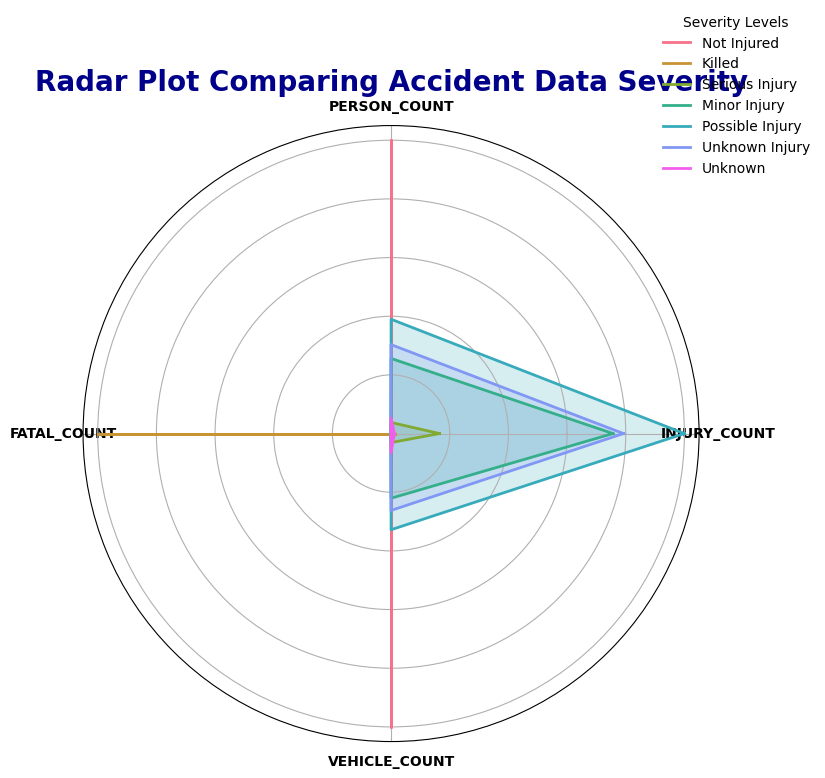

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm

# Feature labels
labels = ['INJURY_COUNT', 'PERSON_COUNT', 'FATAL_COUNT', 'VEHICLE_COUNT']

# Map severity levels to descriptive labels
severity_labels = {
    0: "Not Injured",
    1: "Killed",
    2: "Serious Injury",
    3: "Minor Injury",
    4: "Possible Injury",
    8: "Unknown Injury",
    9: "Unknown"
}

# Group the data by severity level and calculate the sum for the chosen features
grouped = df.groupby('MAX_SEVERITY_LEVEL')[labels].sum()

# Normalize the data (optional) for better comparison
grouped_normalized = (grouped - grouped.min()) / (grouped.max() - grouped.min())

# Function to plot the radar plot
def radar_plot(data, labels, severity_labels):
    # Number of features
    num_vars = len(labels)

    # Compute the angle for each axis
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

    # Close the circle by appending the first value to the end
    angles += angles[:1]

    # Set up the figure and axis
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Use seaborn color palette for smooth lines
    color_palette = sns.color_palette("husl", len(severity_labels))

    # Plot data for each severity level
    for idx, (level, stats) in enumerate(data.iterrows()):
        stats_values = stats.tolist() + [stats.tolist()[0]]  # Close the circle
        ax.plot(angles, stats_values, label=severity_labels.get(level, f"Severity {level}"),
                linewidth=2, linestyle='-', color=color_palette[idx])
        ax.fill(angles, stats_values, alpha=0.2, color=color_palette[idx])

    # Set axis labels (features)
    ax.set_yticklabels([])  # Remove radial ticks
    ax.set_xticks(angles[:-1])  # Remove the last duplicate angle
    ax.set_xticklabels(labels, fontweight='bold')

    # Title and legend
    plt.title("Radar Plot Comparing Accident Data Severity", size=20, weight='bold', color='darkblue')
    plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.2), title="Severity Levels", frameon=False)

    # Display the plot
    plt.show()

# Call the function with the normalized data
radar_plot(grouped_normalized, labels, severity_labels)


## Correlation Heatmap

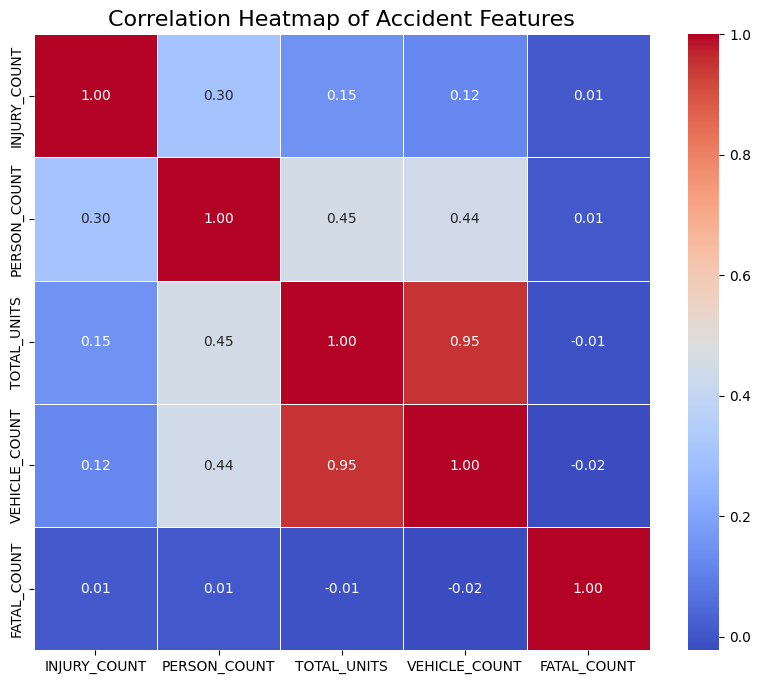

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming df contains the required columns
correlation_matrix = df[['INJURY_COUNT', 'PERSON_COUNT', 'TOTAL_UNITS', 'VEHICLE_COUNT', 'FATAL_COUNT']].corr()

# Plotting the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True, square=True)
plt.title('Correlation Heatmap of Accident Features', fontsize=16)
plt.show()


## Geographical Dist

In [ ]:
# Install folium if not already installed
!pip install folium

import folium
from folium.plugins import HeatMap
import pandas as pd

# Remove rows where either LATITUDE_DECIMAL or LONGITUDE_DECIMAL are NaN
df_clean = df.dropna(subset=['LATITUDE_DECIMAL', 'LONGITUDE_DECIMAL'])

# Create a base map centered around the average latitude and longitude
m = folium.Map(location=[df_clean['LATITUDE_DECIMAL'].mean(), df_clean['LONGITUDE_DECIMAL'].mean()], zoom_start=12)

# Prepare the data for the heatmap: a list of [lat, lon] coordinates for each accident
heat_data = [[row['LATITUDE_DECIMAL'], row['LONGITUDE_DECIMAL']] for index, row in df_clean.iterrows()]

# Add the heatmap to the map
HeatMap(heat_data).add_to(m)

# Display the map
m

<ipython-input-7-b75288485e9d>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['lat_bin'] = pd.cut(df_clean['DEC_LAT'], bins=lat_bins)
<ipython-input-7-b75288485e9d>:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['lon_bin'] = pd.cut(df_clean['DEC_LONG'], bins=lon_bins)
<ipython-input-7-b75288485e9d>:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to

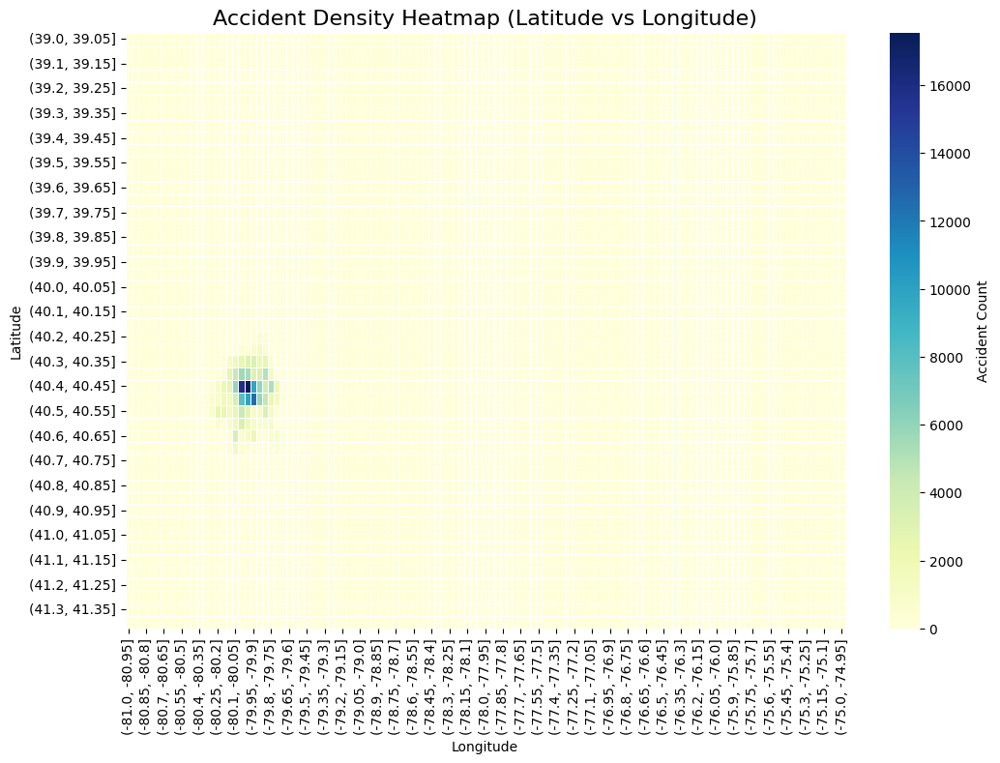

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df has 'DEC_LAT' and 'DEC_LONG' columns
# Remove rows with NaN values in DEC_LAT or DEC_LONG
df_clean = df.dropna(subset=['DEC_LAT', 'DEC_LONG'])

# Define grid size (change this to adjust the resolution)
grid_size = 0.05  # 0.05 degree grid size (you can adjust this)

# Create latitude and longitude bins using pd.cut
lat_min, lat_max = df_clean['DEC_LAT'].min(), df_clean['DEC_LAT'].max()
lon_min, lon_max = df_clean['DEC_LONG'].min(), df_clean['DEC_LONG'].max()

lat_bins = np.arange(lat_min, lat_max, grid_size)
lon_bins = np.arange(lon_min, lon_max, grid_size)

# Add the grid bins to the dataframe
df_clean['lat_bin'] = pd.cut(df_clean['DEC_LAT'], bins=lat_bins)
df_clean['lon_bin'] = pd.cut(df_clean['DEC_LONG'], bins=lon_bins)

# Group by the grid bins and count the number of accidents in each grid cell
grid_counts = df_clean.groupby(['lat_bin', 'lon_bin']).size().reset_index(name='accident_count')

# Pivot the grid counts into a 2D array (grid)
heatmap_data = grid_counts.pivot(index='lat_bin', columns='lon_bin', values='accident_count').fillna(0)

# Plot the heatmap using seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False, cbar_kws={'label': 'Accident Count'}, linewidths=0.5)

# Set labels and title
plt.title("Accident Density Heatmap (Latitude vs Longitude)", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Show the plot
plt.show()

## Bivariate Analysis

<ipython-input-17-ad20e181d916>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].astype('category')
<ipython-input-17-ad20e181d916>:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[numerical_cols] = df[numerical_cols].replace([np.inf, -np.inf], np.nan)  # Replace inf values with NaN


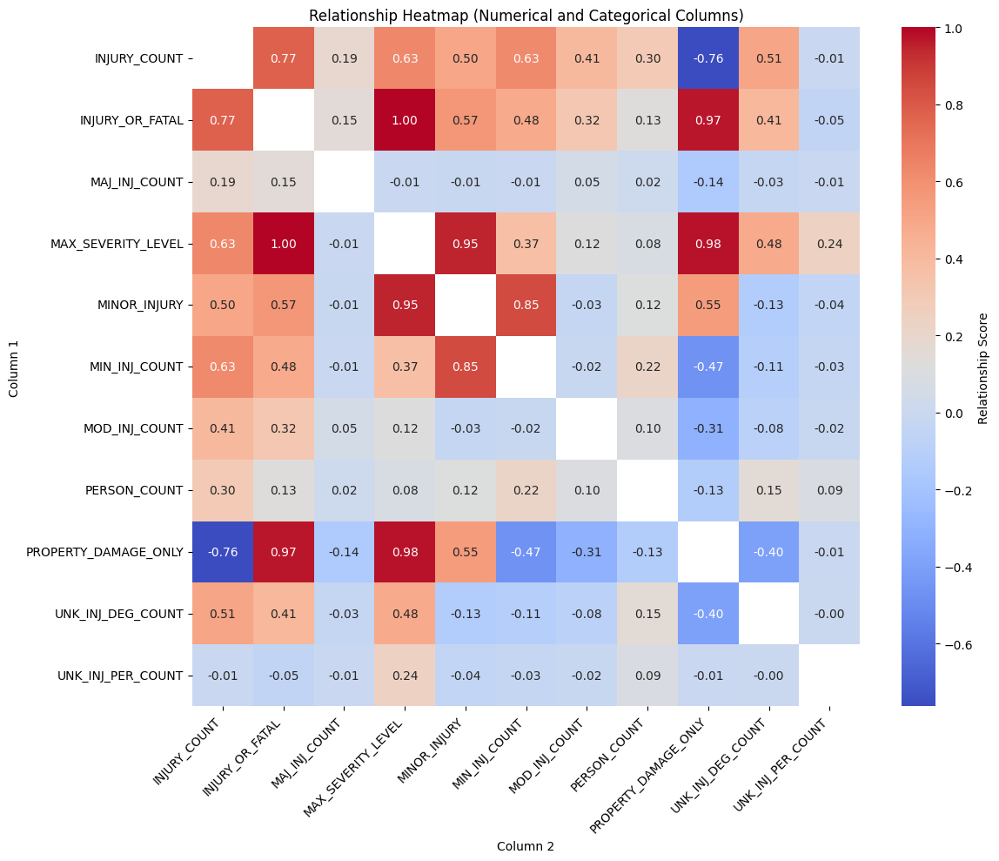

High correlation between INJURY_COUNT and INJURY_OR_FATAL with score 0.77


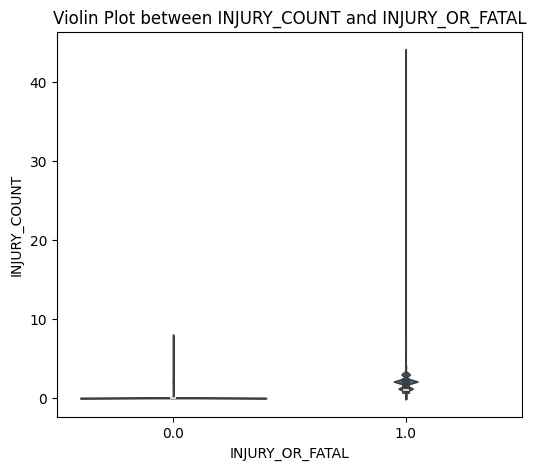

High correlation between INJURY_COUNT and PROPERTY_DAMAGE_ONLY with score -0.76


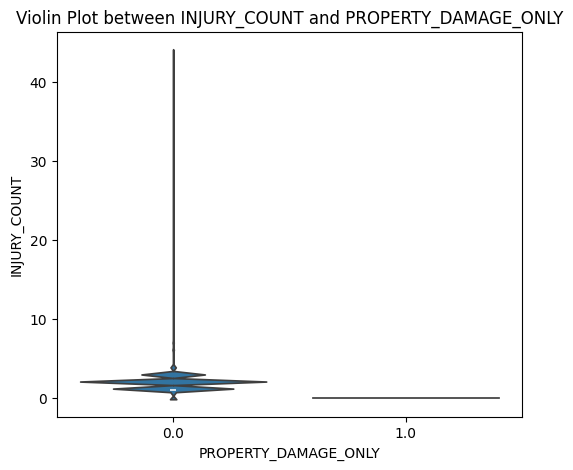

High correlation between MIN_INJ_COUNT and MINOR_INJURY with score 0.85


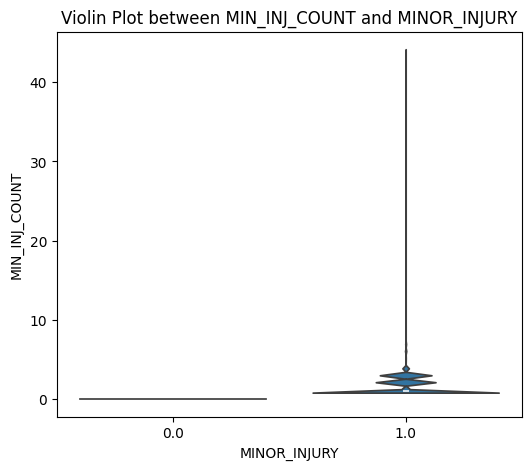

High correlation between INJURY_OR_FATAL and INJURY_COUNT with score 0.77


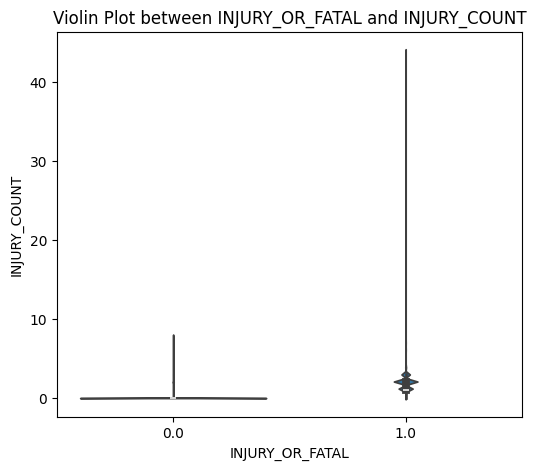

High correlation between INJURY_OR_FATAL and PROPERTY_DAMAGE_ONLY with score 0.97


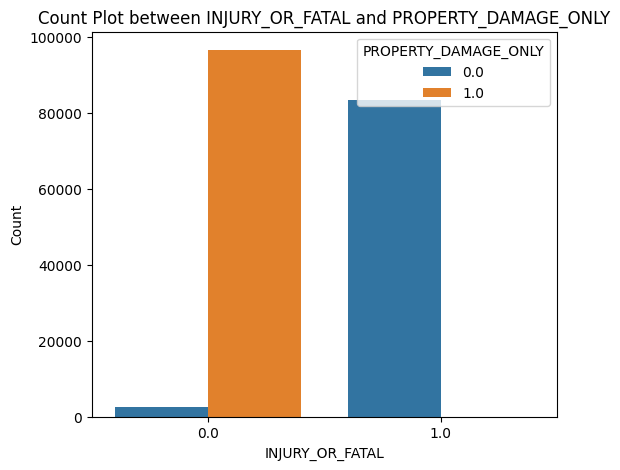

High correlation between INJURY_OR_FATAL and MAX_SEVERITY_LEVEL with score 1.00


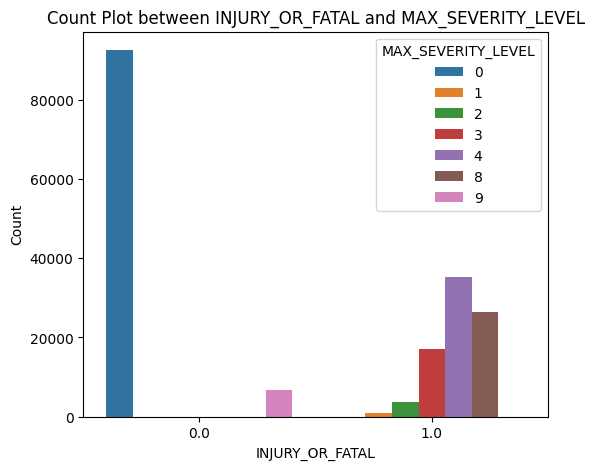

High correlation between MINOR_INJURY and MIN_INJ_COUNT with score 0.85


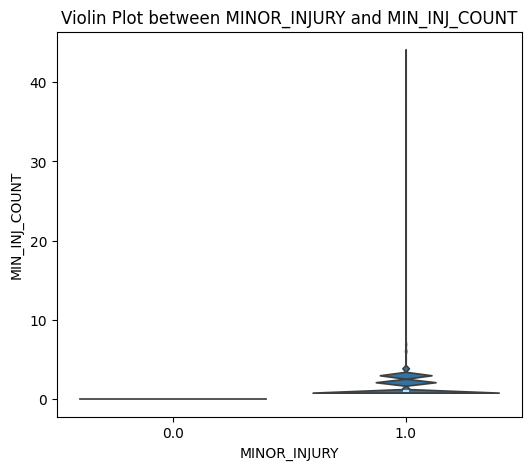

High correlation between MINOR_INJURY and MAX_SEVERITY_LEVEL with score 0.95


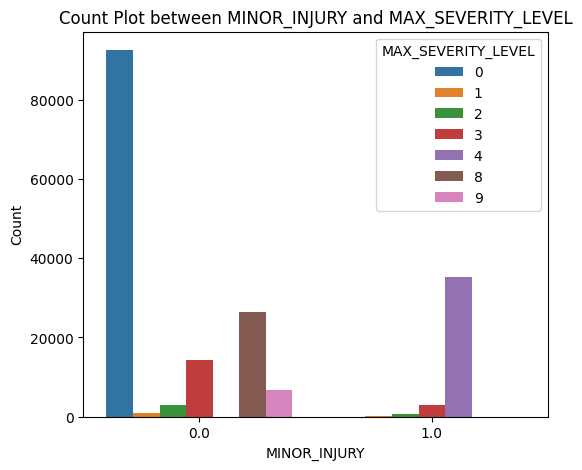

High correlation between PROPERTY_DAMAGE_ONLY and INJURY_COUNT with score -0.76


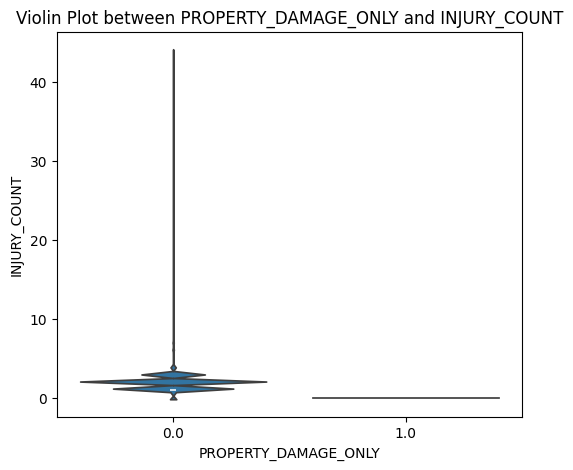

High correlation between PROPERTY_DAMAGE_ONLY and INJURY_OR_FATAL with score 0.97


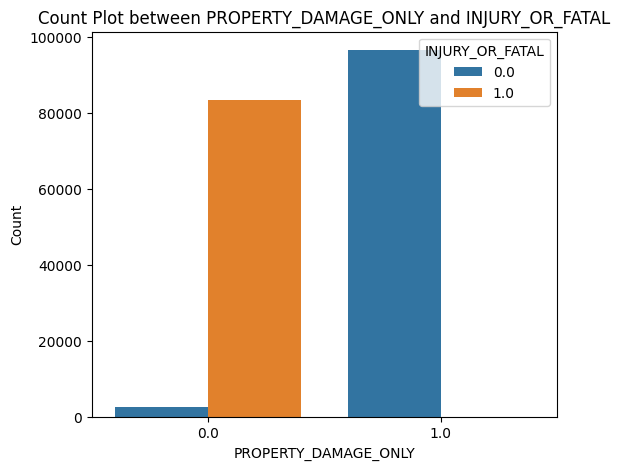

High correlation between PROPERTY_DAMAGE_ONLY and MAX_SEVERITY_LEVEL with score 0.98


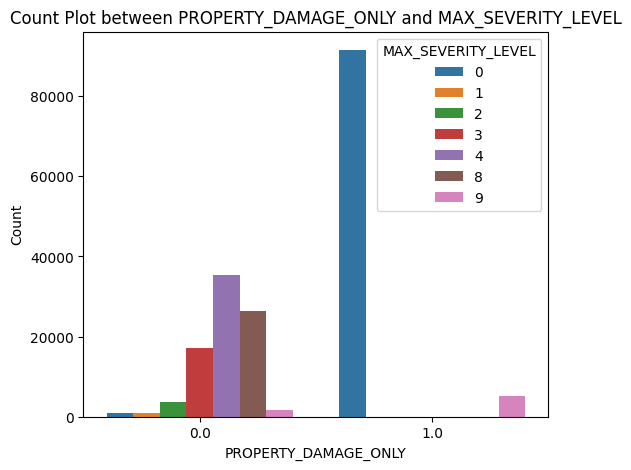

High correlation between MAX_SEVERITY_LEVEL and INJURY_OR_FATAL with score 1.00


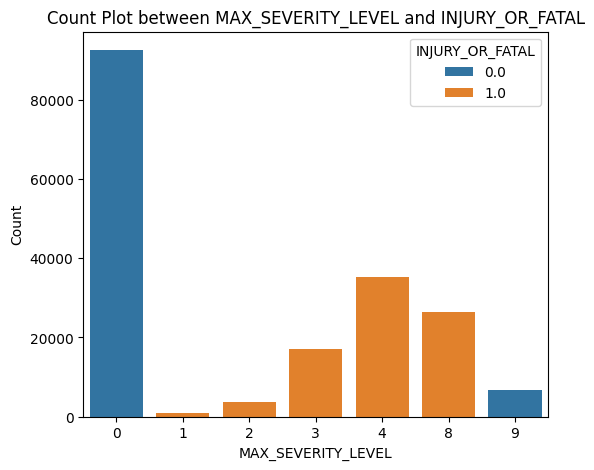

High correlation between MAX_SEVERITY_LEVEL and MINOR_INJURY with score 0.95


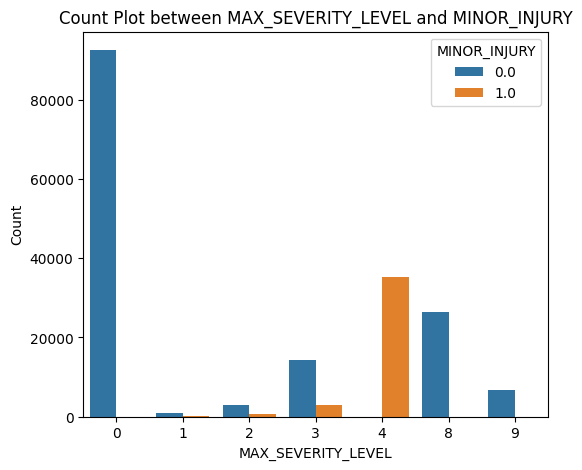

High correlation between MAX_SEVERITY_LEVEL and PROPERTY_DAMAGE_ONLY with score 0.98


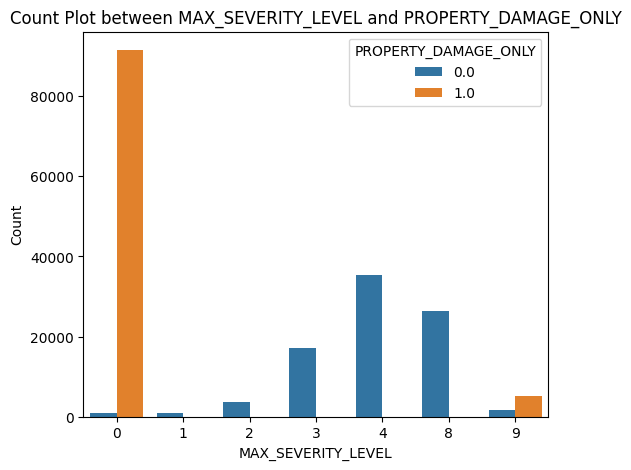

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.preprocessing import LabelEncoder

# Step 1: Load the data
# Assume 'df' is the DataFrame loaded from your file

# Step 2: Define columns as categorical or numerical based on your input
categorical_cols = ["INJURY_OR_FATAL", "MINOR_INJURY", "PROPERTY_DAMAGE_ONLY", "MAX_SEVERITY_LEVEL"]  # Update with actual categorical column names
numerical_cols = ["INJURY_COUNT", "MIN_INJ_COUNT", "MOD_INJ_COUNT", "UNK_INJ_DEG_COUNT", "UNK_INJ_PER_COUNT", "MAJ_INJ_COUNT", "PERSON_COUNT"]

# Step 3: Convert categorical columns to 'category' dtype
for col in categorical_cols:
    df[col] = df[col].astype('category')

# Step 4: Handle missing or infinite values
df[numerical_cols] = df[numerical_cols].replace([np.inf, -np.inf], np.nan)  # Replace inf values with NaN
df = df.dropna(subset=numerical_cols)  # Drop rows with NaN in numerical columns

# Handle categorical missing values
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])  # Fill NaN values with mode for categorical columns

# Step 5: Calculate correlations for numerical columns
correlation_matrix = df[numerical_cols].corr()

# Step 6: Evaluate relationships for categorical and mixed data
def cramers_v(x, y):
    """Calculate Cramér's V for categorical columns."""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    return np.sqrt(chi2 / (n * (min(confusion_matrix.shape) - 1)))

def mixed_relationship(col1, col2):
    """Evaluate relationships between mixed-type columns."""
    try:
        if col1 in numerical_cols and col2 in categorical_cols:
            # Ensure the categorical column is cleanly encoded
            cat_encoded = LabelEncoder().fit_transform(df[col2].astype(str))
            return pointbiserialr(df[col1], cat_encoded)[0]
        elif col1 in categorical_cols and col2 in numerical_cols:
            # Ensure the categorical column is cleanly encoded
            cat_encoded = LabelEncoder().fit_transform(df[col1].astype(str))
            return pointbiserialr(df[col2], cat_encoded)[0]
        elif col1 in categorical_cols and col2 in categorical_cols:
            # Clean both columns for Cramér's V
            return cramers_v(df[col1].astype(str), df[col2].astype(str))
    except Exception as e:
        print(f"Error in processing columns {col1} and {col2}: {e}")
        return np.nan

# Step 7: Pairwise relationships for specified column pairs
results = {}
for col1 in numerical_cols + categorical_cols:  # Restrict iteration to specified columns
    for col2 in numerical_cols + categorical_cols:
        if col1 != col2:  # Skip self-correlation
            if col1 in numerical_cols and col2 in numerical_cols:
                # Numeric-Numeric correlation
                results[(col1, col2)] = df[col1].corr(df[col2])
            elif col1 in categorical_cols or col2 in categorical_cols:
                # Categorical or mixed-type relationship
                results[(col1, col2)] = mixed_relationship(col1, col2)

# Convert results to a DataFrame for visualization
relationship_df = pd.DataFrame.from_dict(results, orient='index', columns=['Relationship Score'])

# Reset index to get column names as separate columns
relationship_df = relationship_df.reset_index()
relationship_df[['Column 1', 'Column 2']] = pd.DataFrame(relationship_df['index'].tolist(), index=relationship_df.index)
relationship_df = relationship_df.drop(columns='index')

# Pivot the DataFrame to create a matrix for the heatmap
heatmap_data = relationship_df.pivot(index='Column 1', columns='Column 2', values='Relationship Score')

# Create a heatmap for visualizing relationships
plt.figure(figsize=(12, 10))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'label': 'Relationship Score'})
plt.title("Relationship Heatmap (Numerical and Categorical Columns)")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 8: Visualize highly correlated pairs
threshold = 0.7  # Set a threshold for high correlation

for (col1, col2), score in results.items():
    if abs(score) >= threshold:
        print(f"High correlation between {col1} and {col2} with score {score:.2f}")

        if col1 in numerical_cols and col2 in numerical_cols:
            # For numeric-numeric high correlation, use scatter plot
            plt.figure(figsize=(6, 5))
            sns.scatterplot(x=df[col1], y=df[col2])
            plt.title(f"Scatter Plot between {col1} and {col2}")
            plt.xlabel(col1)
            plt.ylabel(col2)
            plt.show()

        elif col1 in categorical_cols and col2 in numerical_cols:
            # For categorical-numerical high correlation, use violin plot
            plt.figure(figsize=(6, 5))
            sns.violinplot(x=df[col1], y=df[col2])
            plt.title(f"Violin Plot between {col1} and {col2}")
            plt.xlabel(col1)
            plt.ylabel(col2)
            plt.show()

        elif col1 in numerical_cols and col2 in categorical_cols:
            # For numerical-categorical high correlation, use violin plot
            plt.figure(figsize=(6, 5))
            sns.violinplot(x=df[col2], y=df[col1])
            plt.title(f"Violin Plot between {col1} and {col2}")
            plt.xlabel(col2)
            plt.ylabel(col1)
            plt.show()

        elif col1 in categorical_cols and col2 in categorical_cols:
            # For categorical-categorical high correlation, use count plot
            plt.figure(figsize=(6, 5))
            sns.countplot(x=df[col1], hue=df[col2])
            plt.title(f"Count Plot between {col1} and {col2}")
            plt.xlabel(col1)
            plt.ylabel('Count')
            plt.show()
-

<h2> Feature Enginnering & Model Trainning and Model Testing </h2>

In [31]:
sorted_dataset.columns


Index(['_id', 'CRASH_CRN', 'DISTRICT', 'CRASH_COUNTY', 'MUNICIPALITY',
       'POLICE_AGCY', 'CRASH_YEAR', 'CRASH_MONTH', 'DAY_OF_WEEK',
       'TIME_OF_DAY',
       ...
       'ROADWAY_COUNTY', 'LANE_COUNT', 'RDWY_ORIENT', 'ROAD_OWNER', 'ROUTE',
       'SPEED_LIMIT', 'SEGMENT', 'OFFSET', 'STREET_NAME', 'TOT_INJ_COUNT'],
      dtype='object', length=176)

In [32]:
col_names = ["INJURY_COUNT", "TOTAL_UNITS", "PERSON_COUNT", "HOUR_OF_DAY", "WEATHER", "ADVERSE_WEATHER", "TIME_OF_DAY", "", "LATITUDE",
             "LONGITUDE", "FATAL_COUNT", "MAX_SEVERITY_LEVEL"]

<h2> Feature Engineering for classification Model </h2>

In [ ]:
df_2 = sorted_dataset.copy()

# Separate features and target
x = df_2.drop('MAX_SEVERITY_LEVEL', axis=1)
y = df_2['MAX_SEVERITY_LEVEL']

# 2. Convert non-numeric columns to numeric using One-Hot Encoding
x = pd.get_dummies(x, drop_first=True)

# 3. Train a Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x, y)

# Extract feature importance
feature_importances = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Feature Importances:\n", feature_importances)

# 4. Select top N important features (e.g., top 2)
top_features = feature_importances['Feature'][:7].tolist()
X_selected = x[top_features]

print("\nSelected Features:\n", X_selected.head())

Feature Importances:
                       Feature  Importance
137           INJURY_OR_FATAL    0.084720
145              MINOR_INJURY    0.083626
31               INJURY_COUNT    0.077965
79       PROPERTY_DAMAGE_ONLY    0.068553
34              MIN_INJ_COUNT    0.066248
...                       ...         ...
11061  LONGITUDE_80 16:35.844    0.000000
3593    LATITUDE_40 27:55.112    0.000000
3589    LATITUDE_40 27:54.237    0.000000
6375   LONGITUDE_79 49:37.318    0.000000
2458    LATITUDE_40 25:57.720    0.000000

[13695 rows x 2 columns]

Selected Features:
    INJURY_OR_FATAL  MINOR_INJURY  INJURY_COUNT  PROPERTY_DAMAGE_ONLY  \
0                0             0             0                     1   
1                1             0             1                     0   
2                1             1             1                     0   
3                1             0             1                     0   
4                0             0             0                     

<h2> Model Train Test </h2>

In [ ]:


# Split data using selected features
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)

# Train classification model
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Make predictions and evaluate
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy using top features: {accuracy:.2f}")



Accuracy using top features: 0.95


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
svm = SVC(kernel='linear', C=1.0, random_state=42)

# Train the SVM classifier
svm.fit(X_train, y_train)

# Make predictions on the test set
y_pred = svm.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9487734487734488

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.98      0.97      1327
           1       1.00      0.80      0.89        15
           2       0.00      0.00      0.00        54
           3       0.96      1.00      0.98       290
           4       0.99      1.00      1.00       745
           8       0.86      1.00      0.92       234
           9       0.67      0.41      0.51       107

    accuracy                           0.95      2772
   macro avg       0.78      0.74      0.75      2772
weighted avg       0.93      0.95      0.94      2772


Confusion Matrix:
 [[1305    0    0    0    0    0   22]
 [   0   12    0    2    0    1    0]
 [   0    0    0   11    6   37    0]
 [   0    0    0  290    0    0    0]
 [   0    0    0    0  745    0    0]
 [   0    0    0    0    0  234    0]
 [  63    0    0    0    0    0   44]]


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


<h2> Feature Engineering for Regression Model </h2>

In [ ]:
from sklearn.ensemble import RandomForestRegressor
df_3 = sorted_dataset.copy()

# Separate features and target
x = df_3.drop('INJURY_COUNT', axis=1)
y = df_3['INJURY_COUNT']

# 2. Convert non-numeric columns to numeric using One-Hot Encoding
x = pd.get_dummies(x, drop_first=True)

# 3. Train a Random Forest Classifier
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(x, y)

# Extract feature importance
feature_importances = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Feature Importances:\n", feature_importances)

# 4. Select top N important features (e.g., top 2)
top_features = feature_importances['Feature'][:10].tolist()
X_selected = x[top_features]

print("\nSelected Features:\n", X_selected.head())

Feature Importances:
                      Feature  Importance
79      PROPERTY_DAMAGE_ONLY    0.557570
33             MIN_INJ_COUNT    0.224178
34         UNK_INJ_DEG_COUNT    0.071140
32             MOD_INJ_COUNT    0.045024
49        MAX_SEVERITY_LEVEL    0.022824
...                      ...         ...
4768   LATITUDE_40 32:44.923    0.000000
4769   LATITUDE_40 32:44.950    0.000000
4770   LATITUDE_40 32:45.137    0.000000
4772   LATITUDE_40 32:45.600    0.000000
13694    STREET_NAME_ZERO ST    0.000000

[13695 rows x 2 columns]

Selected Features:
    PROPERTY_DAMAGE_ONLY  MIN_INJ_COUNT  UNK_INJ_DEG_COUNT  MOD_INJ_COUNT  \
0                     1              0                  0              0   
1                     0              0                  0              1   
2                     0              1                  0              0   
3                     0              0                  0              1   
4                     1              0                  0  

<h2> Regression Model </h2>

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# Assuming X_selected and y are defined properly

# Split data using selected features
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)

# Train regression model
clf = RandomForestRegressor(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate using regression metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"R² Score: {r2:.2f}")


Mean Squared Error: 0.03
Mean Absolute Error: 0.02
R² Score: 0.97
